# 04 - Evaluation and error analysis
**Day 3 - part 1** | estimated time: 2 - 2.5 h (after the 45-minute seminar)

Yesterday you trained a lung segmentation model and got *one* number: a validation Dice.
Today we open the **test set** for the first time and ask a harder question: *can we trust
this model, and when should we not?* A single average Dice is not an evaluation. We will
measure every case separately, with several metrics in **physical units**, look at the
failures, split the results by subgroup, stress-test the model, compare it with a classical
baseline and write down its limitations. These notes go into the model card on day 4.

**Learning objectives.** After this notebook you can:
* run a model on a whole test set and keep per-case predictions for analysis;
* compute Dice, IoU, Hausdorff distance (HD95) and average surface distance, and say when each one misleads;
* turn masks into a clinically meaningful number (lung area in cm2) and judge agreement with Bland-Altman;
* find, view and categorise the worst cases, remembering that the reference masks are silver standard;
* stratify results (position in the scan, nodules, pixel spacing) and respect small group sizes;
* apply and judge post-processing (largest connected components, hole filling);
* stress-test a model with realistic perturbations and compare it with a threshold baseline.

| Marker | Meaning |
|---|---|
| ✏️ **Exercise** | mandatory, fill the `____` blanks, then run the check cell (hidden hints below each exercise) |
| 🔍 **Explore** | small "change this and re-run" experiments, for everybody |
| 🚀 **Challenge** | additional task with a solution in the teachers' notebook |
| 🌶️ **Going further** | open-ended, optional |
| 🧠 **Question** | answer in words (discuss with your neighbour) |
| ⚠️ **Pitfall** / 📚 **Read more** | classic mistakes / links |

## 0. Setup, data, model

In [1]:
# Setup: install what is missing (quiet). On Kaggle/Colab most of it is already there.
import importlib.util, subprocess, sys

def ensure(module, pip_name):
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

for module, pip_name in [("monai", "monai[nibabel]"), ("nibabel", "nibabel"), ("scipy", "scipy"),
                         ("skimage", "scikit-image"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    ensure(module, pip_name)

In [2]:
import os
from pathlib import Path

# --- Debug run: tiny & fast, to check that everything works before a real run ---
FAST = os.environ.get("HI_FAST", "0") == "1"   # set FAST = True by hand to debug quickly

# --- Where is the data? -----------------------------------------------------------
def find_data_dir() -> Path:
    """Locate the course dataset (folder containing images/, labels/, metadata.csv)."""
    candidates = [os.environ.get("HI_DATA_DIR")]
    candidates += sorted(Path("/kaggle/input").glob("*/")) if Path("/kaggle/input").exists() else []
    candidates += sorted(Path("/kaggle/input").glob("*/*/")) if Path("/kaggle/input").exists() else []
    candidates += ["data/luna16-lung-slices", "../data/luna16-lung-slices", "data/synthetic", "../data/synthetic"]
    for c in candidates:
        if c and (Path(c) / "metadata.csv").exists():
            return Path(c)
    raise FileNotFoundError(
        "Dataset not found. On Kaggle: 'Add input' and attach the course dataset. "
        "Elsewhere: download it (see README) and set HI_DATA_DIR."
    )

DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("HI_WORK_DIR", "/kaggle/working" if Path("/kaggle/working").exists() else "outputs"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
print(f"data: {DATA_DIR}\noutputs: {WORK_DIR}\nFAST mode: {FAST}")

data: /home/claude/data/real_test
outputs: /tmp/hi_real2
FAST mode: False


In [3]:
import json, math, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.ndimage as ndi
import torch
import torch.nn.functional as F

import monai
from monai.data import Dataset
from monai.metrics import DiceMetric, compute_average_surface_distance, compute_hausdorff_distance
from monai.networks.utils import one_hot
from monai.transforms import (Compose, EnsureChannelFirstd, EnsureTyped, FillHoles, KeepLargestConnectedComponent,
                              Lambdad, LoadImage, LoadImaged, RandAffined, RandGaussianNoised, Resize, Resized,
                              ScaleIntensityRanged)
from monai.utils import set_determinism

set_determinism(seed=42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
MAX_TEST = 12 if FAST else None     # FAST: never look at more than 12 test cases
N_BOOT = 200 if FAST else 2000      # number of bootstrap resamples (challenge)
print(f"MONAI {monai.__version__} | torch {torch.__version__} | device {device}")

MONAI 1.6.1 | torch 2.5.1+cpu | device cpu


### Recap of the "given" pipeline (from day 1-2, do not change)
The preprocessing must be **exactly** the one used for training, otherwise we would be
evaluating a different model (this is called *training-serving skew*, more on day 4).
The data lists use the course splits: `subset` 0-6 train, 7-8 validation, **9 test**.

In [4]:
def lungs_only(x):
    """1 = right lung, 2 = left lung -> 1; everything else (incl. trachea) -> 0."""
    return ((x == 1) | (x == 2)).to(x.dtype)


def get_transforms(img_size, hu_min=-1000, hu_max=400, augment=False):
    keys = ["image", "label"]
    t = [
        LoadImaged(keys=keys),
        EnsureChannelFirstd(keys=keys),
        Lambdad(keys="label", func=lungs_only),
        ScaleIntensityRanged(keys="image", a_min=hu_min, a_max=hu_max, b_min=0.0, b_max=1.0, clip=True),
        Resized(keys=keys, spatial_size=(img_size, img_size), mode=("bilinear", "nearest")),
    ]
    if augment:
        t += [
            RandAffined(keys=keys, prob=0.5, rotate_range=0.15, scale_range=0.1, translate_range=img_size * 0.05,
                        mode=("bilinear", "nearest"), padding_mode="zeros"),
            RandGaussianNoised(keys="image", prob=0.2, std=0.02),
        ]
    t += [EnsureTyped(keys=keys)]
    return Compose(t)


def make_datalists(data_dir: Path):
    meta = pd.read_csv(data_dir / "metadata.csv")
    def rows(mask):
        return [{"image": str(data_dir / "images" / f"{c}.nii.gz"),
                 "label": str(data_dir / "labels" / f"{c}.nii.gz"), "case_id": c}
                for c in meta.loc[mask, "case_id"]]
    return rows(meta.subset <= 6), rows(meta.subset.isin([7, 8])), rows(meta.subset == 9)


train_files, val_files, test_files = make_datalists(DATA_DIR)
test_files = test_files[:MAX_TEST]
print(f"train {len(train_files)} | val {len(val_files)} | test {len(test_files)} cases")

train 63 | val 18 | test 8 cases


### Find and load the model
We use the model you saved on day 2 (it lives in `WORK_DIR/models/<name>`). If there is none,
we fall back to the teachers' model shipped with the dataset, so everybody can continue.
The input size is **always read from the model's `config.json`**, never hard-coded.

In [5]:
def find_model_dirs():
    """All model folders (config.json + model.pt) we can see, most specific first."""
    roots = [os.environ.get("HI_MODEL_DIR"), WORK_DIR / "models", "/kaggle/input", DATA_DIR / "pretrained"]
    found = []
    for r in roots:
        if r and Path(r).exists():
            dirs = [p.parent for p in Path(r).rglob("config.json") if (p.parent / "model.pt").exists()]
            # within one place: the most recently saved model first
            found += sorted(dirs, key=lambda d: (d / "model.pt").stat().st_mtime, reverse=True)

    def is_binary_2d(d):   # the course contract: 2D, 1 input channel (HU window), 2 output channels
        k = json.loads((d / "config.json").read_text()).get("arch_kwargs", {})
        return (k.get("spatial_dims"), k.get("in_channels"), k.get("out_channels")) == (2, 1, 2)

    return [d for d in found if is_binary_2d(d)]

def load_model(model_dir, device="cpu"):
    cfg = json.loads((Path(model_dir) / "config.json").read_text())
    net = getattr(monai.networks.nets, cfg["arch"])(**cfg["arch_kwargs"])
    net.load_state_dict(torch.load(Path(model_dir) / "model.pt", map_location=device, weights_only=True))
    return net.to(device).eval(), cfg

In [6]:
model_dirs = find_model_dirs()
for i, d in enumerate(model_dirs):
    print(f"[{i}] {d}")
MODEL_DIR = model_dirs[0]          # newest of your models, else the teachers' one. 🔍 change the index to evaluate another
model, cfg = load_model(MODEL_DIR, device)

IMG_SIZE = cfg["preprocessing"]["img_size"][0]
HU_MIN, HU_MAX = cfg["preprocessing"]["hu_min"], cfg["preprocessing"]["hu_max"]
test_tf = get_transforms(IMG_SIZE, HU_MIN, HU_MAX)

print(f"\nUSING: {MODEL_DIR}")
print(f"name={cfg['name']} | trained by: {cfg.get('trained_by')} | date: {cfg.get('date')}")
print(f"input {IMG_SIZE}x{IMG_SIZE}, HU window [{HU_MIN}, {HU_MAX}] | validation Dice stored in config: {cfg.get('metrics', {}).get('val_dice')}")
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

nvImageCodec is not available; skipping pydicom decoder plugin registration.


[0] /tmp/hi_real2/models/unet-baseline
[1] /home/claude/data/real_test/pretrained/unet-baseline

USING: /tmp/hi_real2/models/unet-baseline
name=unet-baseline | trained by: your name | date: 2026-11-18
input 256x256, HU window [-1000, 400] | validation Dice stored in config: 0.9684
parameters: 1,625,161


/usr/local/lib/python3.13/site-packages/monai/data/image_reader.py:1166: UserWarning: NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
  warnings.warn(


## 1. Predict the whole test set, once
From now on the test set is **opened**. Rule of the game: we *describe* the model with it, we do
not *tune* the model on it. Every decision we make after looking at test errors (a threshold,
a post-processing step, a model choice) makes the test numbers optimistic. For decisions use the
validation set (day 3 part 2 and day 4 do exactly this).

We predict every test case **once** and keep everything in memory: image, reference mask,
softmax probability of "lung" and the predicted mask. All later sections work on these arrays.

### ✏️ Exercise 1.1 - the prediction function
Complete `predict_batch`: put the model in evaluation mode, switch off gradient tracking and
take the class with the highest score (`argmax` over the channel dimension).

<details>
<summary>💡 Hint 1</summary>

Two things behave differently at inference time: layers such as dropout/normalisation (`model.train()` vs
`model.eval()`), and memory: we do not need gradients, so we wrap the forward pass in a context manager.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`model.eval()`, `with torch.no_grad():` and `logits.argmax(dim=1)` (dim 1 = the channel dimension of `(N, C, H, W)`).

</details>

In [7]:
def predict_batch(model, x, batch_size=16):
    """x: float tensor (N, 1, H, W) -> (probability of lung (N, H, W) float32, predicted mask (N, H, W) uint8)."""
    model.eval()
    probs, preds = [], []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            logits = model(x[i:i + batch_size].to(device))
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu())
            preds.append(logits.argmax(dim=1).cpu())
    return torch.cat(probs).numpy(), torch.cat(preds).numpy().astype(np.uint8)


def predict_dataset(model, files, transforms):
    """Run the whole pipeline on a list of cases; everything stays at the network resolution."""
    items = list(Dataset(files, transforms))
    x = torch.stack([torch.as_tensor(np.asarray(it["image"])) for it in items])      # (N, 1, H, W)
    y = np.stack([np.asarray(it["label"])[0] for it in items]).astype(np.uint8)       # (N, H, W)
    prob, pred = predict_batch(model, x)
    return {"case_id": [f["case_id"] for f in files], "image": x[:, 0].numpy(), "label": y, "prob": prob, "pred": pred}


res = predict_dataset(model, test_files, test_tf)
print({k: (v.shape if hasattr(v, "shape") else len(v)) for k, v in res.items()})

{'case_id': 8, 'image': (8, 256, 256), 'label': (8, 256, 256), 'prob': (8, 256, 256), 'pred': (8, 256, 256)}


In [8]:
# Check 1.1
_x = torch.as_tensor(res["image"][:3, None])
_prob, _pred = predict_batch(model, _x)
assert not model.training, "the model is still in training mode: call model.eval()"
assert _pred.shape == res["image"][:3].shape and set(np.unique(_pred)) <= {0, 1}, "pred must be a (N,H,W) mask with values 0/1"
assert _prob.min() >= 0 and _prob.max() <= 1, "prob should be a softmax probability"
print("✅ Exercise 1.1 passed")

✅ Exercise 1.1 passed


### Pixel size at the network resolution
Distances and areas must be in **millimetres**, not pixels: a 10-pixel error is 7 mm on one
scanner and 5 mm on another. But our masks live at the *network* resolution (e.g. 256x256), not at
the original one (512x512 with `spacing_x/y` from `metadata.csv`). Resizing the whole slice to
`IMG_SIZE` pixels makes every pixel larger by the factor `original_size / IMG_SIZE`.

### ✏️ Exercise 1.2 - pixel size at the network resolution
Compute `px_x` and `px_y` (mm per network pixel) for every test case.

<details>
<summary>💡 Hint 1</summary>

The field of view in mm is `spacing * size` and it does not change when we resize.
So `px = field_of_view / IMG_SIZE`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`px_x = spacing_x * size_x / IMG_SIZE`, and the same with `y`.

</details>

In [9]:
meta = pd.read_csv(DATA_DIR / "metadata.csv").set_index("case_id")
test_meta = meta.loc[res["case_id"]].reset_index()      # same order as the predictions

test_meta["px_x"] = test_meta["spacing_x"] * test_meta["size_x"] / IMG_SIZE
test_meta["px_y"] = test_meta["spacing_y"] * test_meta["size_y"] / IMG_SIZE
test_meta[["case_id", "spacing_x", "size_x", "px_x", "px_y", "slice_thickness", "z_rel", "has_nodule"]]

,case_id,spacing_x,size_x,px_x,px_y,slice_thickness,z_rel,has_nodule
0,case_0010,0.617188,512,1.234376,1.234376,0.70,0.4647,1
1,case_0020,0.781250,512,1.562500,1.562500,1.00,0.6934,1
2,case_0030,0.613281,512,1.226562,1.226562,1.00,0.5591,1
3,case_0040,0.710938,512,1.421876,1.421876,1.00,0.6918,1
4,case_0050,0.744141,512,1.488282,1.488282,1.00,0.5485,1
5,case_0060,0.595703,512,1.191406,1.191406,1.25,0.4887,1
6,case_0070,0.703125,512,1.406250,1.406250,2.50,0.3699,1
7,case_0080,0.638672,512,1.277344,1.277344,0.75,0.5090,1


In [10]:
# Check 1.2
assert np.allclose(test_meta["px_x"] * IMG_SIZE, test_meta["spacing_x"] * test_meta["size_x"]), "px_x * IMG_SIZE must be the field of view in mm"
assert np.allclose(test_meta["px_y"] * IMG_SIZE, test_meta["spacing_y"] * test_meta["size_y"]), "px_y * IMG_SIZE must be the field of view in mm"
print("✅ Exercise 1.2 passed")

✅ Exercise 1.2 passed


Let us look at a few cases first. Remember: `imshow(img.T)` gives the standard radiological view
(patient's right on the left of the screen), because our arrays are indexed `[x, y]` in LPS+ order.
Green = reference contour, red = predicted contour.

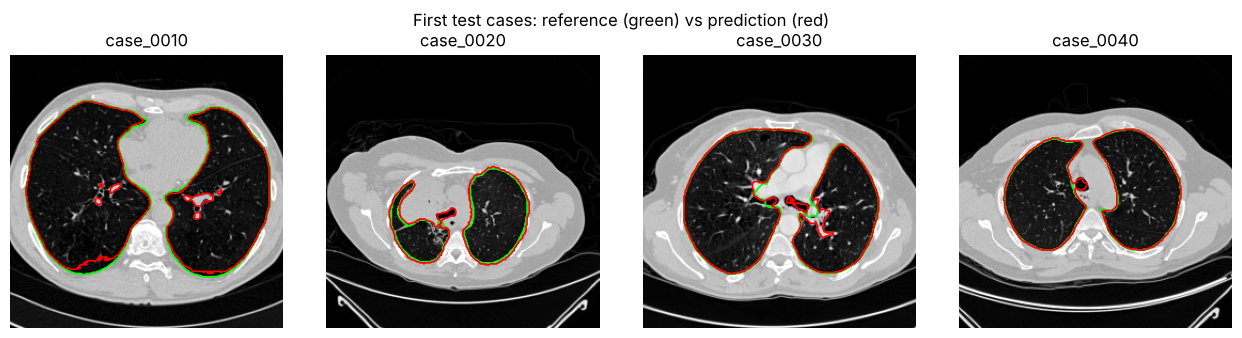

In [11]:
def overlay(ax, img, gt=None, pred=None):
    """Image with reference (green) and predicted (red) contours."""
    ax.imshow(img.T, cmap="gray", vmin=0, vmax=1)
    for m, color in ((gt, "lime"), (pred, "red")):
        if m is not None and 0 < m.sum() < m.size:
            ax.contour(m.T.astype(float), levels=[0.5], colors=color, linewidths=1.2)
    ax.axis("off")

n_show = min(4, len(test_files))
fig, axes = plt.subplots(1, n_show, figsize=(3.2 * n_show, 3.4), squeeze=False)
for j, ax in enumerate(axes[0]):
    overlay(ax, res["image"][j], res["label"][j], res["pred"][j])
    ax.set_title(res["case_id"][j])
plt.suptitle("First test cases: reference (green) vs prediction (red)")
plt.tight_layout()
plt.show()

## 2. Overlap metrics: Dice, IoU, and why the mean is not enough
**Dice** = 2 |P ∩ G| / (|P| + |G|), where P is the predicted and G the reference set of pixels.
You wrote it on day 1; now we use it *per case*.

### ✏️ Exercise 2.1 - per-case Dice with numpy
Complete `dice_np`. When the denominator is zero (both masks empty) the metric is *undefined*:
return `np.nan` instead of pretending it is 0 or 1. We will see why this matters.

<details>
<summary>💡 Hint 1</summary>

The intersection counts pixels where **both** masks are 1; the denominator is the sum of the two mask sizes.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`inter = np.logical_and(pred, gt).sum()` and `denom = pred.sum() + gt.sum()`.

</details>

In [12]:
def dice_np(pred, gt):
    """Dice of two binary masks (any shape). NaN if both are empty."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    denom = pred.sum() + gt.sum()
    return np.nan if denom == 0 else 2.0 * inter / denom

as_onehot = lambda m: one_hot(torch.as_tensor(m)[:, None].long(), num_classes=2)          # (N,H,W) -> (N,2,H,W)

In [13]:
# Check 2.1: unit tests + agreement with MONAI's DiceMetric on the real predictions
a = np.zeros((10, 10), bool); a[:5] = True
b = np.zeros((10, 10), bool); b[2:7] = True
assert np.isclose(dice_np(a, a), 1.0) and np.isclose(dice_np(a, ~a), 0.0), "identical -> 1, disjoint -> 0"
assert np.isclose(dice_np(a, b), 0.6), "5 px overlap 3 of 5 rows each: 2*30/100 = 0.6"
assert np.isnan(dice_np(np.zeros((4, 4)), np.zeros((4, 4)))), "both empty -> NaN"

dice = np.array([dice_np(p, g) for p, g in zip(res["pred"], res["label"])])
dice_monai = DiceMetric(include_background=False, reduction="none")(as_onehot(res["pred"]), as_onehot(res["label"]))[:, 0].numpy()
assert np.allclose(dice, dice_monai, equal_nan=True, atol=1e-5), "your Dice differs from monai.metrics.DiceMetric"
print("✅ Exercise 2.1 passed - per-case Dice:", np.round(dice, 3))

✅ Exercise 2.1 passed - per-case Dice: [0.968 0.946 0.976 0.987 0.971 0.959 0.992 0.969]


### IoU (Jaccard) and its relation to Dice
IoU = |P ∩ G| / |P ∪ G|. Dice and IoU are monotonically related, so they **rank cases identically**.

In [14]:
def iou_np(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    union = np.logical_or(pred, gt).sum()
    return np.nan if union == 0 else np.logical_and(pred, gt).sum() / union

iou = np.array([iou_np(p, g) for p, g in zip(res["pred"], res["label"])])
print("IoU      :", np.round(iou, 3))
print("D/(2-D)  :", np.round(dice / (2 - dice), 3))

IoU      : [0.937 0.897 0.954 0.974 0.944 0.922 0.985 0.941]
D/(2-D)  : [0.937 0.897 0.954 0.974 0.944 0.922 0.985 0.941]


> 🧠 **Question:** the two lines above are equal. Derive why (`IoU = Dice / (2 - Dice)`) and say what it
> implies: if both rank the cases identically, why do papers still report both, and which one is
> "harsher" on an imperfect segmentation?

**Answer.** With I = |P ∩ G| and |P ∪ G| = |P| + |G| - I we get Dice = 2I / (|P| + |G|) and IoU = I / (|P| + |G| - I).
Substituting |P| + |G| = 2I / Dice gives IoU = Dice / (2 - Dice). The function is monotonic, so rankings of single
cases are identical, and IoU <= Dice always (Dice 0.9 -> IoU 0.82). IoU is the harsher one, and it is the metric
used by detection challenges (and by some segmentation papers) for historical reasons. Averages can differ in order
between *models*, though: the mean of a nonlinear function is not the function of the mean. The important message:
report which one you use, and never compare a Dice to an IoU.

### Mean vs median vs the whole distribution
The classical report is "mean Dice = 0.9x". Look at the same numbers as a distribution.

/tmp/ipykernel_22150/1818417411.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(v, vert=True, widths=0.5, showfliers=False)


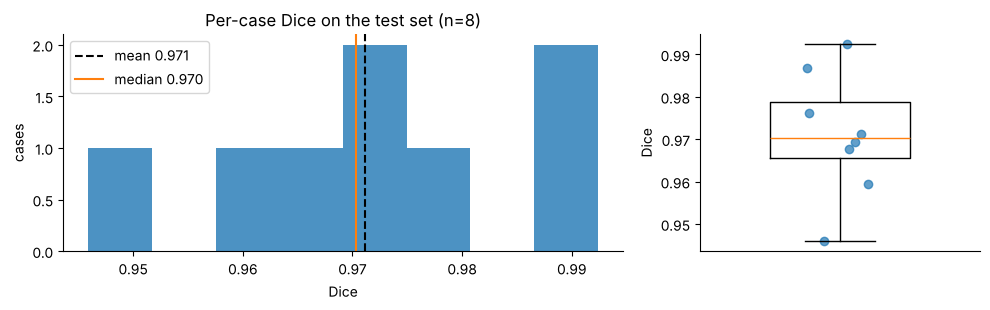

validation Dice stored in config: 0.9684 | test mean: 0.971 | test median: 0.970 | worst: 0.946


In [15]:
def distribution_plot(values, title, xlabel="Dice"):
    v = np.asarray(values, float)
    v = v[~np.isnan(v)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [2, 1]})
    axes[0].hist(v, bins=min(20, max(3, len(v))), color="tab:blue", alpha=0.8)
    axes[0].axvline(v.mean(), color="k", ls="--", label=f"mean {v.mean():.3f}")
    axes[0].axvline(np.median(v), color="tab:orange", label=f"median {np.median(v):.3f}")
    axes[0].set_xlabel(xlabel); axes[0].set_ylabel("cases"); axes[0].legend(); axes[0].set_title(title)
    axes[1].boxplot(v, vert=True, widths=0.5, showfliers=False)
    axes[1].scatter(1 + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v, alpha=0.7, color="tab:blue")
    axes[1].set_xticks([]); axes[1].set_ylabel(xlabel)
    plt.tight_layout(); plt.show()

distribution_plot(dice, f"Per-case Dice on the test set (n={len(dice)})")
print(f"validation Dice stored in config: {cfg.get('metrics', {}).get('val_dice')} | test mean: {np.nanmean(dice):.3f} | "
      f"test median: {np.nanmedian(dice):.3f} | worst: {np.nanmin(dice):.3f}")

> 🧠 **Question:** the stored validation Dice and the test mean are close (or not). Is that enough to call the
> model "good"? Which two numbers from the line above would you want to see next to the mean in a paper
> and why? (Hint: think of a screening programme where one missed lung in 20 is a problem.)

**Answer.** The mean is dominated by the many easy mid-chest slices. A model that is perfect on 95% of
cases and fails completely on 5% still has a mean Dice of 0.95. Report the **median** (what a typical case
looks like) and a **tail** statistic (worst case, 5th percentile, or the fraction of cases below a clinically chosen
threshold). Also: the validation set was used to *select* the checkpoint, so its Dice is slightly optimistic; the
test set is the only unbiased estimate, and with a few dozen cases it comes with a wide confidence interval
(see the bootstrap challenge in section 7).

### 🔍 Explore
* Re-run the distribution plot with `iou` instead of `dice`. Same ranking, different scale.
* Re-load the model with `MODEL_DIR = model_dirs[1]` (if you have another one) and compare distributions.
* Which single case would you look at first? Write down its `case_id` - we will check your intuition in section 6.

## 3. Boundary metrics: Hausdorff distance and average surface distance
Dice counts overlapping pixels, so it is almost blind to **where** the errors are. Two predictions with
the same Dice can be clinically very different: one has a slightly rough boundary, the other
has a blob in the wrong organ. *Surface-distance* metrics measure the distance (in mm) between the
boundaries:

* **Hausdorff distance (HD)**: for each boundary pixel of one mask, the distance to the closest boundary
  pixel of the other; HD is the **maximum** over both directions. One outlier blob decides everything.
* **HD95**: the 95th percentile instead of the maximum, so a handful of stray pixels does not dominate.
* **Average surface distance (ASD)**: the mean of those distances; a typical boundary error.

Let us look at a toy example before using them. Two imperfect predictions of the same "two lungs".

Dice A = 0.925 | Dice B = 0.930  (blob radius 6 px)


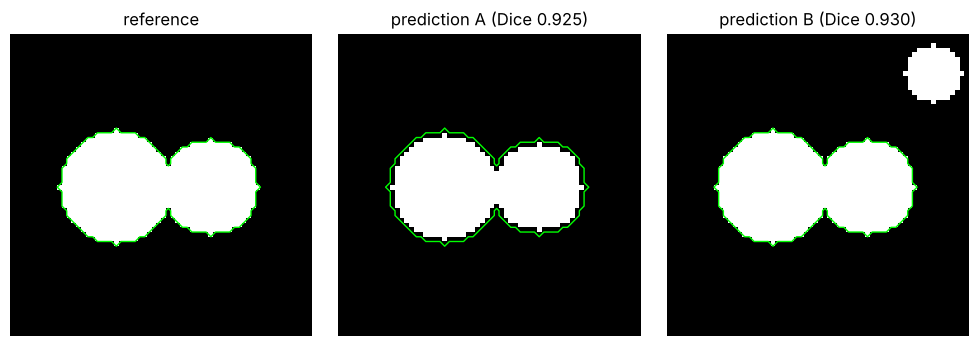

In [16]:
def disc(shape, cx, cy, r):
    xx, yy = np.mgrid[:shape[0], :shape[1]]
    return (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2

S = 64
gt_toy = disc((S, S), 22, 32, 12) | disc((S, S), 42, 32, 10)       # two "lungs"
pred_a = ndi.binary_erosion(gt_toy)                                  # A: boundary 1 px inside, otherwise perfect
d_a = dice_np(pred_a, gt_toy)
# B: perfect lungs + a far-away blob; we pick the blob radius so that Dice(B) is as close as possible to Dice(A)
blobs = {r: gt_toy | disc((S, S), 56, 8, r) for r in range(1, 14)}
r_best = min(blobs, key=lambda r: abs(dice_np(blobs[r], gt_toy) - d_a))
pred_b = blobs[r_best]
print(f"Dice A = {d_a:.3f} | Dice B = {dice_np(pred_b, gt_toy):.3f}  (blob radius {r_best} px)")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, m, t in zip(axes, [gt_toy, pred_a, pred_b], ["reference", f"prediction A (Dice {d_a:.3f})", f"prediction B (Dice {dice_np(pred_b, gt_toy):.3f})"]):
    ax.imshow(m.T, cmap="gray"); ax.contour(gt_toy.T.astype(float), levels=[0.5], colors="lime", linewidths=1); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

Same Dice, very different clinical meaning. Prediction B would, for example, send a radiotherapy plan
into the shoulder. Now the metrics that can *see* it.

### ✏️ Exercise 3.1 - surface distances in millimetres with MONAI
Complete `surface_metrics`. MONAI's `compute_hausdorff_distance` and `compute_average_surface_distance`
expect **one-hot** tensors `(N, C, H, W)` and take the pixel **spacing in mm** (one value per axis), so the result
is directly in mm. We use `include_background=False` (class 1 = lung only).
Empty masks have no surface: we return NaN and handle it in the tables.

<details>
<summary>💡 Hint 1</summary>

Read the signature: `compute_hausdorff_distance(y_pred, y, include_background, distance_metric, percentile, directed, spacing)`.
`percentile=None` would give the plain maximum.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`percentile=95` and `spacing=spacing_mm`, with `spacing_mm = [px_x, px_y]` (axis 0 = x, axis 1 = y, as in our arrays).

</details>

In [17]:
def surface_metrics(pred, gt, spacing_mm, percentile=95):
    """(HD at `percentile`, mean symmetric surface distance), both in mm. NaN if a mask is empty."""
    if pred.sum() == 0 or gt.sum() == 0:
        return np.nan, np.nan
    p, g = as_onehot(pred[None]), as_onehot(gt[None])                    # (1, 2, H, W)
    hd = compute_hausdorff_distance(p, g, include_background=False, percentile=percentile, spacing=spacing_mm)
    asd = compute_average_surface_distance(p, g, include_background=False, symmetric=True, spacing=spacing_mm)
    return float(hd[0, 0]), float(asd[0, 0])

In [18]:
# Check 3.1
sq = np.zeros((40, 40), np.uint8); sq[10:20, 10:20] = 1
sq_shift = np.zeros((40, 40), np.uint8); sq_shift[13:23, 10:20] = 1          # shifted by 3 px along axis 0
hd_t, asd_t = surface_metrics(sq_shift, sq, [2.0, 2.0], percentile=100)
assert np.isclose(surface_metrics(sq, sq, [1.0, 1.0])[0], 0.0), "identical masks -> distance 0"
assert abs(hd_t - 6.0) < 0.5, f"3 px at 2 mm/px should be about 6 mm, got {hd_t:.2f}: is the spacing used?"
assert 0 < asd_t <= hd_t, "ASD must be positive and not larger than HD"
assert all(np.isnan(v) for v in surface_metrics(np.zeros_like(sq), sq, [1.0, 1.0])), "empty prediction -> NaN"
print(f"✅ Exercise 3.1 passed (3 px shift at 2 mm/px: HD = {hd_t:.1f} mm, ASD = {asd_t:.1f} mm)")

/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


✅ Exercise 3.1 passed (3 px shift at 2 mm/px: HD = 6.0 mm, ASD = 3.0 mm)


In [19]:
# The toy example again, now with distances (1.5 mm per pixel)
rows = []
for name, m in [("A: rough boundary", pred_a), ("B: far blob", pred_b)]:
    hd95, asd = surface_metrics(m, gt_toy, [1.5, 1.5], 95)
    hd100, _ = surface_metrics(m, gt_toy, [1.5, 1.5], 100)
    rows.append({"prediction": name, "Dice": dice_np(m, gt_toy), "HD95 (mm)": hd95, "HD100 (mm)": hd100, "ASD (mm)": asd})
pd.DataFrame(rows).round(3).set_index("prediction")

,Dice,HD95 (mm),HD100 (mm),ASD (mm)
prediction,,,,
A: rough boundary,0.925,1.5,1.50,1.500
B: far blob,0.930,33.0,35.56,3.633


Dice is the same, HD is not. Note that the blob also moves the *average* distance only a little: that is
the reason why we look at **several** metrics, each with its own blind spot.

> 🧠 **Question:** when is Dice misleading *even with a perfect-looking contour*? Think about (a) very small
> structures, (b) slices near the lung apex or base, where the lung is a few pixels wide, (c) what a boundary error
> of 1 pixel does to Dice for a structure of 10 pixels vs 10 000 pixels.

**Answer.** Dice is a *relative* overlap, so its sensitivity depends on size: for a disc of radius r an error of
one boundary pixel changes the area by about 2/r, so Dice falls by about 1/r. On a big lung (r ~ 100 px) a 1 px
error costs 0.01; on an apex slice where each lung is a 10-px blob it costs 0.1 - a perfectly acceptable contour
(sub-millimetre) looks like a failure. Conversely, on tiny structures a missing blob barely changes the mean
Dice but changes the clinical answer. Therefore: report distance metrics in mm next to Dice, and look at strata
(apex/base vs middle). For empty masks Dice is undefined (0/0): decide on a convention and report it.

### 🔍 Explore
* In the toy example, shrink the blob (change `range(1, 14)` to `range(1, 3)`) and compare HD95 and HD100.
  Why does HD95 miss a tiny blob while HD100 does not? (How many boundary pixels does the blob contribute?)
* Change the spacing to `[1.5, 0.75]` (anisotropic pixels). Which way do the distances change?
* Call `surface_metrics(..., percentile=50)`: what does this value represent?

Now apply the distances to the test set, **in mm**, using each case's own pixel size.

/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


HD95 (mm): [30.9 11.1 15.6  1.5 13.4 14.7  1.4 15.8]
ASD  (mm): [3.78 2.25 1.79 0.84 1.74 2.56 0.47 1.94]
cases where a distance is undefined (empty mask): 0


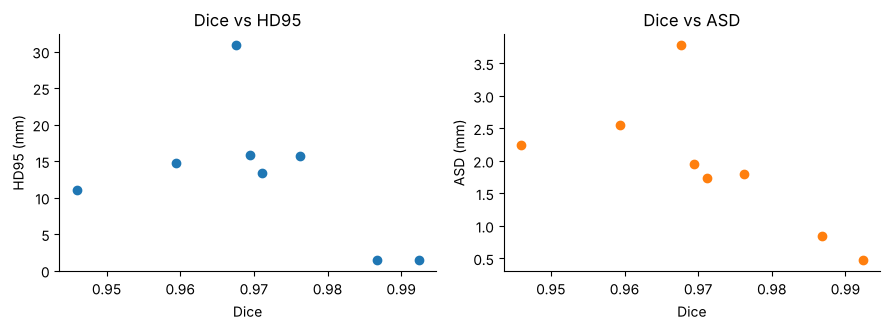

In [20]:
spacings = test_meta[["px_x", "px_y"]].to_numpy()
hd95 = np.array([surface_metrics(p, g, list(s))[0] for p, g, s in zip(res["pred"], res["label"], spacings)])
asd = np.array([surface_metrics(p, g, list(s))[1] for p, g, s in zip(res["pred"], res["label"], spacings)])
print("HD95 (mm):", np.round(hd95, 1))
print("ASD  (mm):", np.round(asd, 2))
print(f"cases where a distance is undefined (empty mask): {int(np.isnan(hd95).sum())}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].scatter(dice, hd95); axes[0].set_xlabel("Dice"); axes[0].set_ylabel("HD95 (mm)"); axes[0].set_title("Dice vs HD95")
axes[1].scatter(dice, asd, color="tab:orange"); axes[1].set_xlabel("Dice"); axes[1].set_ylabel("ASD (mm)"); axes[1].set_title("Dice vs ASD")
plt.tight_layout(); plt.show()

> ⚠️ **Pitfall:** a correlation between Dice and HD95 is expected, but the cases *off the trend* (high Dice
> with a large HD95, as in prediction B) are exactly the ones that Dice alone hides. Also never average
> a metric that contains `inf`/`NaN` silently: `np.nanmean` hides the failures, `np.mean` returns NaN. Count them.

## 4. A clinically meaningful quantity: lung area (volume in 3D)
Radiologists and clinicians rarely care about Dice. They care about numbers like **lung volume** (emphysema, ILD
follow-up, surgical planning). With a 2D slice we can compute the **lung area in cm2**; in 3D you would multiply
the area of each slice by the slice thickness and sum: `volume = n_voxels * dx * dy * dz`. The same code, one
more spacing.

### ✏️ Exercise 4.1 - area in cm2
Complete `area_cm2(mask, px_x, px_y)`: number of foreground pixels times the area of one pixel. Careful with the units
(1 cm = 10 mm).

<details>
<summary>💡 Hint 1</summary>

Area of one pixel in mm2 is `px_x * px_y`. How many mm2 are in a cm2?

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`mask.sum() * px_x * px_y / 100`.

</details>

In [21]:
def area_cm2(mask, px_x, px_y):
    """Foreground area in cm2 (px_x, px_y: pixel size in mm)."""
    return float(mask.astype(bool).sum() * px_x * px_y / 100.0)

In [22]:
# Check 4.1
assert np.isclose(area_cm2(np.ones((10, 10)), 0.5, 0.5), 0.25), "100 px of 0.5x0.5 mm = 25 mm2 = 0.25 cm2"
area_gt = np.array([area_cm2(g, *s) for g, s in zip(res["label"], spacings)])
area_pred = np.array([area_cm2(p, *s) for p, s in zip(res["pred"], spacings)])
# sanity check against the area stored in metadata.csv (computed at full resolution): resizing explains small differences
rel = np.abs(area_gt - test_meta["lung_area_mm2"].to_numpy() / 100) / np.maximum(test_meta["lung_area_mm2"].to_numpy() / 100, 1e-6)
assert np.median(rel) < 0.2, f"reference area differs from metadata.csv by {np.median(rel):.0%}: check the units/pixel size"
print("✅ Exercise 4.1 passed - area (cm2), reference:", np.round(area_gt, 0), "| median deviation from metadata.csv:", f"{np.median(rel):.1%}")

✅ Exercise 4.1 passed - area (cm2), reference: [363. 138. 239. 240. 289. 323. 297. 269.] | median deviation from metadata.csv: 0.1%


### Predicted vs reference area, and the Bland-Altman plot
A scatter plot with the identity line shows *correlation*, which is easy to get: any two things that grow with body size
correlate. The **Bland-Altman plot** asks the clinical question: how much do the two methods *disagree*? We plot the
difference (pred - ref) against the mean of the two. The **bias** is the mean difference; the **95% limits of
agreement** are `bias ± 1.96 * SD` of the differences: a new measurement will lie within them 95% of the time.

### ✏️ Exercise 4.2 - bias and limits of agreement
<details>
<summary>💡 Hint 1</summary>

`diff` is already given. Bias is its mean; the spread is its standard deviation (use `ddof=1`, the sample SD).

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`bias = diff.mean()`, `sd = diff.std(ddof=1)`, `loa_low, loa_high = bias - 1.96 * sd, bias + 1.96 * sd`.

</details>

In [23]:
def bland_altman(ref, pred):
    """Return mean of the two methods, difference (pred - ref), bias, lower and upper 95% limits of agreement."""
    ref, pred = np.asarray(ref, float), np.asarray(pred, float)
    mean, diff = (ref + pred) / 2, pred - ref
    bias = diff.mean()
    sd = diff.std(ddof=1) if len(diff) > 1 else 0.0
    loa_low, loa_high = bias - 1.96 * sd, bias + 1.96 * sd
    return mean, diff, bias, loa_low, loa_high

mean_a, diff_a, bias, loa_low, loa_high = bland_altman(area_gt, area_pred)

In [24]:
# Check 4.2
assert np.isclose(bias, np.mean(area_pred - area_gt)), "bias is the mean of (pred - ref)"
assert loa_low <= bias <= loa_high, "the bias must lie between the limits of agreement"
_, _, b0, lo0, hi0 = bland_altman(np.array([1., 2, 3, 4]), np.array([2., 3, 4, 5]))
assert np.isclose(b0, 1.0) and np.isclose(lo0, 1.0) and np.isclose(hi0, 1.0), "constant offset of 1 -> bias 1, no spread"
print(f"✅ Exercise 4.2 passed - bias {bias:+.2f} cm2, limits of agreement [{loa_low:+.2f}, {loa_high:+.2f}] cm2")

✅ Exercise 4.2 passed - bias -6.87 cm2, limits of agreement [-32.58, +18.84] cm2


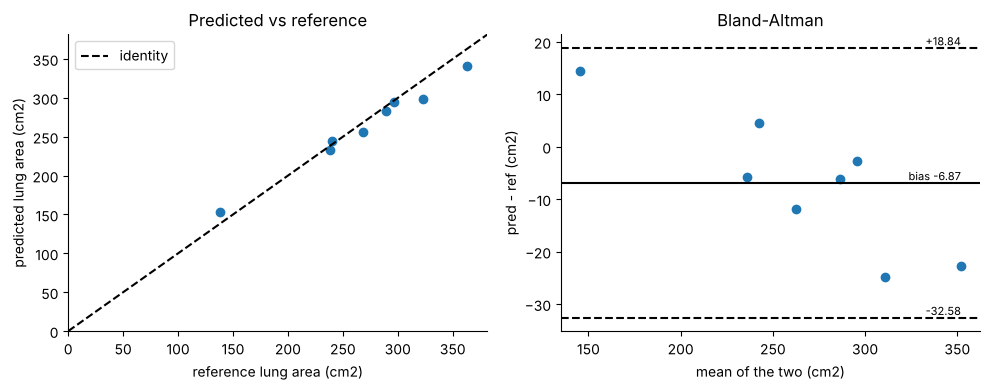

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
lim = [0, max(area_gt.max(), area_pred.max()) * 1.05]
axes[0].scatter(area_gt, area_pred); axes[0].plot(lim, lim, "k--", label="identity")
axes[0].set(xlabel="reference lung area (cm2)", ylabel="predicted lung area (cm2)", title="Predicted vs reference", xlim=lim, ylim=lim)
axes[0].legend()
axes[1].scatter(mean_a, diff_a)
for y, ls, lab in [(bias, "-", f"bias {bias:+.2f}"), (loa_low, "--", f"{loa_low:+.2f}"), (loa_high, "--", f"{loa_high:+.2f}")]:
    axes[1].axhline(y, color="k", ls=ls); axes[1].text(mean_a.max(), y, lab, va="bottom", ha="right", fontsize=8)
axes[1].set(xlabel="mean of the two (cm2)", ylabel="pred - ref (cm2)", title="Bland-Altman")
plt.tight_layout(); plt.show()

> 🧠 **Question:** the limits of agreement are [`loa_low`, `loa_high`] cm2. A lung of 200 cm2 on a mid-chest slice: is
> that error clinically acceptable for (a) a screening programme, (b) monitoring emphysema progression over a year?
> Who decides the threshold? Also: why does a *systematic* bias (large `bias`) matter more for follow-up studies than random error?

**Answer.** There is no universal threshold: it is set by the *clinical question* and the *biological variability*.
Screening (is there a lung at all?) tolerates large errors; monitoring a change of a few percent per year needs an
error much smaller than that change, otherwise measurement noise is bigger than disease progression. A systematic bias is
harmless if the same model measures both time points, but dangerous when the model is updated or a different scanner is used
(the bias changes, and it looks like disease). Random error shrinks when averaging many measurements; bias does not. The
acceptable limits are defined together with clinicians, ideally from the inter-observer variability of human readers.

## 5. One table to rule them all
Everything we computed goes in a **per-case table** merged with the metadata. All the questions of the rest of the notebook
(which cases fail? why? for which patients?) are questions to this table. We wrap the metrics in one function so we can
re-use it on other predictions (post-processed, perturbed, baseline).

In [26]:
def evaluate_masks(preds, gts, meta):
    """Per-case metrics of predicted masks `preds` vs `gts` (both (N, H, W)); `meta` has px_x, px_y per case."""
    rows = []
    for p, g, m in zip(preds, gts, meta.itertuples()):
        sp = [m.px_x, m.px_y]
        hd, asd_ = surface_metrics(p, g, sp)
        pb, gb = p.astype(bool), g.astype(bool)
        rows.append({"case_id": m.case_id, "dice": dice_np(p, g), "iou": iou_np(p, g), "hd95_mm": hd, "asd_mm": asd_,
                     "area_gt_cm2": area_cm2(g, *sp), "area_pred_cm2": area_cm2(p, *sp),
                     "fp_px": int((pb & ~gb).sum()), "fn_px": int((~pb & gb).sum())})
    out = pd.DataFrame(rows)
    out["area_err_cm2"] = out["area_pred_cm2"] - out["area_gt_cm2"]
    return out


metrics = evaluate_masks(res["pred"], res["label"], test_meta)
df = test_meta.merge(metrics, on="case_id")
assert np.allclose(df["dice"], dice, equal_nan=True) and np.allclose(df["hd95_mm"], hd95, equal_nan=True)
df[["case_id", "subset", "z_rel", "slice_thickness", "has_nodule", "dice", "iou", "hd95_mm", "asd_mm", "area_gt_cm2", "area_pred_cm2", "fp_px", "fn_px"]].round(3)

,case_id,subset,z_rel,slice_thickness,has_nodule,dice,iou,hd95_mm,asd_mm,area_gt_cm2,area_pred_cm2,fp_px,fn_px
0,case_0010,9,0.465,0.70,1,0.968,0.937,30.859,3.777,363.368,340.574,0,1496
1,case_0020,9,0.693,1.00,1,0.946,0.897,11.065,2.249,138.110,152.612,619,25
2,case_0030,9,0.559,1.00,1,0.976,0.954,15.636,1.794,238.622,232.935,184,562
3,case_0040,9,0.692,1.00,1,0.987,0.974,1.481,0.835,240.000,244.508,270,47
4,case_0050,9,0.548,1.00,1,0.971,0.944,13.432,1.737,289.388,283.186,233,513
5,case_0060,9,0.489,1.25,1,0.959,0.922,14.737,2.556,323.379,298.638,17,1760
6,case_0070,9,0.370,2.50,1,0.992,0.985,1.406,0.468,296.750,294.100,47,181
7,case_0080,9,0.509,0.75,1,0.969,0.941,15.789,1.944,268.563,256.652,127,857


In [27]:
LOWER_IS_BETTER = {"hd95_mm", "asd_mm"}

def summary_table(df, cols=("dice", "iou", "hd95_mm", "asd_mm")):
    """mean, std, median, 'bad tail' (5th percentile; 95th for distances) and worst case, plus number of undefined values."""
    out = {}
    for c in cols:
        v = df[c].dropna()
        bad = c in LOWER_IS_BETTER
        out[c] = {"mean": v.mean(), "std": v.std(), "median": v.median(),
                  "bad tail (5%)": v.quantile(0.95 if bad else 0.05), "worst": v.max() if bad else v.min(),
                  "undefined (NaN)": int(df[c].isna().sum())}
    return pd.DataFrame(out).round(3)

summary_table(df)

,dice,iou,hd95_mm,asd_mm
mean,0.971,0.944,13.051,1.920
std,0.015,0.028,9.318,1.021
median,0.970,0.942,14.084,1.869
bad tail (5%),0.951,0.906,25.585,3.350
worst,0.946,0.897,30.859,3.777
undefined (NaN),0.000,0.000,0.000,0.000


Read the table from the bottom up: the *worst* and *bad tail* rows are what the deployment will hit. With only a handful of
cases the 5th percentile is almost the minimum; with the full test set it is a stable number.

## 6. Error analysis: look at the failures
Numbers tell you *that* something fails; only images tell you *why*. We build a gallery of the worst and the best cases.
In the error map: **red = false positive** (model says lung, reference says not), **blue = false negative** (the reference has lung,
the model misses it), grey = true positive.

### ✏️ Exercise 6.1 - which are the worst cases?
Write `worst_cases(df, metric, k, higher_is_better)` returning the row indices of the `k` worst cases for a chosen metric.
For Dice the worst are the *lowest*; for HD95 the *highest*. A case where the metric is NaN (e.g. empty prediction) is a failure too:
it must come first, not last (`sort_values` puts NaN last by default!).

<details>
<summary>💡 Hint 1</summary>

We first replace NaN by the worst possible value (`-inf` when higher is better, `+inf` otherwise), then sort. Which direction is
`ascending` when the worst case is the smallest value?

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`ascending=higher_is_better`: if higher is better, the worst are at the start of an ascending sort.

</details>

In [28]:
def worst_cases(df, metric, k=3, higher_is_better=True):
    """Row indices (labels) of the k worst cases by `metric`. NaN counts as the worst value."""
    score = df[metric].fillna(-np.inf if higher_is_better else np.inf)
    order = score.sort_values(ascending=higher_is_better)
    return list(order.index[:k])

In [29]:
# Check 6.1
_t = pd.DataFrame({"m": [0.9, np.nan, 0.2, 0.7]})
assert worst_cases(_t, "m", 2, higher_is_better=True) == [1, 2], "for a 'higher is better' metric: NaN first, then the lowest"
assert worst_cases(_t, "m", 2, higher_is_better=False) == [1, 0], "for a 'lower is better' metric: NaN first, then the highest"
print("✅ Exercise 6.1 passed")

✅ Exercise 6.1 passed


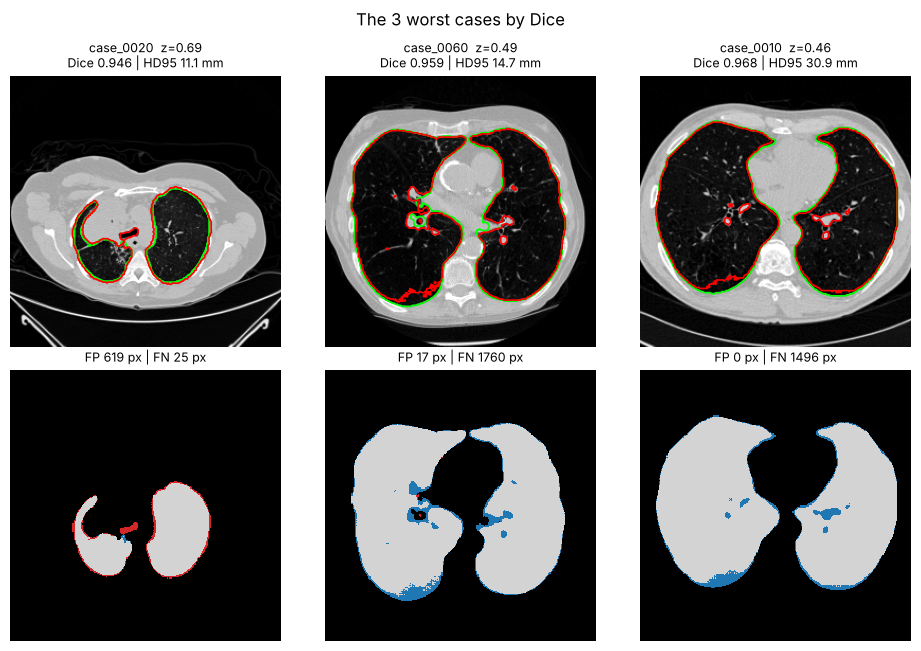

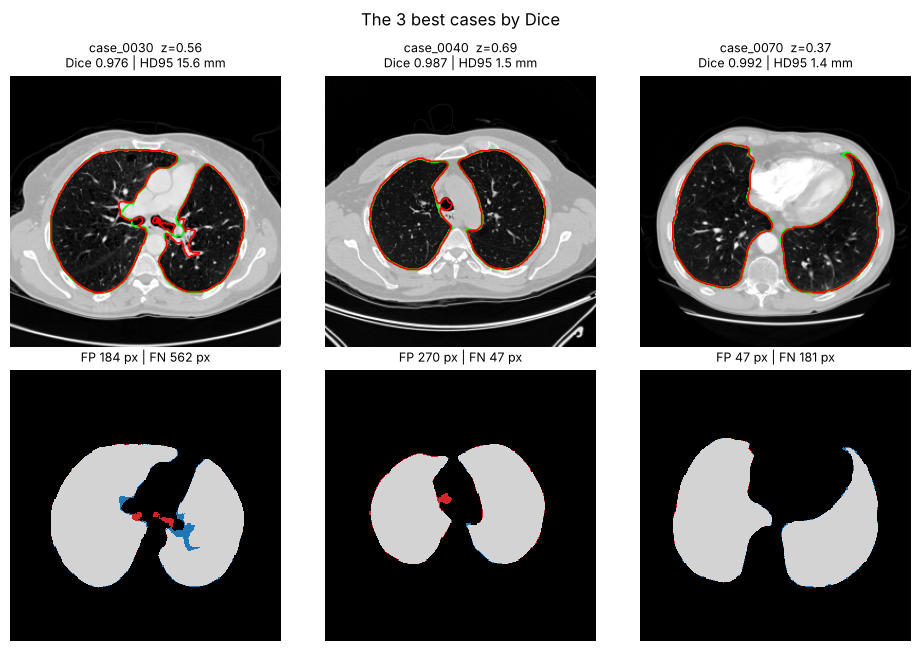

In [30]:
K = min(3, max(1, len(df) // 2))
worst_ids = worst_cases(df, "dice", K, higher_is_better=True)
best_ids = worst_cases(df, "dice", K, higher_is_better=False)[::-1]     # "worst" of the reversed order = best

def show_cases(idxs, preds=None, title="", table=None):
    """Row 1: image + reference (green) + prediction (red). Row 2: error map (red FP, blue FN, grey TP)."""
    from matplotlib.colors import ListedColormap
    preds = res["pred"] if preds is None else preds
    table = df if table is None else table          # per-case metrics matching `preds`
    fig, axes = plt.subplots(2, len(idxs), figsize=(3.2 * len(idxs), 6.6), squeeze=False)
    for j, i in enumerate(idxs):
        gt, pr = res["label"][i], preds[i]
        overlay(axes[0, j], res["image"][i], gt, pr)
        r = table.loc[i]
        axes[0, j].set_title(f"{r.case_id}  z={r.z_rel:.2f}\nDice {r.dice:.3f} | HD95 {r.hd95_mm:.1f} mm", fontsize=9)
        err = gt.astype(int) + 2 * pr.astype(int)                 # 1 = FN, 2 = FP, 3 = TP
        axes[1, j].imshow(err.T, cmap=ListedColormap(["black", "tab:blue", "tab:red", "lightgray"]), vmin=0, vmax=3, interpolation="nearest")
        axes[1, j].set_title(f"FP {int(r.fp_px)} px | FN {int(r.fn_px)} px", fontsize=9); axes[1, j].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_cases(worst_ids, title=f"The {K} worst cases by Dice")
show_cases(best_ids, title=f"The {K} best cases by Dice")

### Is it the model or the label?
The LUNA16 lung masks were produced by an **automatic algorithm** and not by hand ("silver standard"). The consequence: when
the model and the reference disagree, *sometimes the model is right*. A model can never be scored higher than its reference.
One more diagnostic helps: the reference also contains the trachea and main bronchi (label 3), which we trained the model to *ignore*.
How many of the false-positive pixels fall on the trachea?

In [31]:
mc_tf = Compose([LoadImaged(keys="label"), EnsureChannelFirstd(keys="label"),
                 Resized(keys="label", spatial_size=(IMG_SIZE, IMG_SIZE), mode="nearest")])
label_mc = np.stack([np.asarray(mc_tf({"label": f["label"]})["label"])[0] for f in test_files]).astype(np.uint8)
df["fp_trachea_px"] = [int(((p == 1) & (l == 3)).sum()) for p, l in zip(res["pred"], label_mc)]
diag_cols = ["case_id", "z_rel", "has_nodule", "area_gt_cm2", "dice", "hd95_mm", "fp_px", "fn_px", "fp_trachea_px"]
df.loc[worst_ids, diag_cols].round(3)

nvImageCodec is not available; skipping pydicom decoder plugin registration.


/usr/local/lib/python3.13/site-packages/monai/data/image_reader.py:1166: UserWarning: NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
  warnings.warn(


,case_id,z_rel,has_nodule,area_gt_cm2,dice,hd95_mm,fp_px,fn_px,fp_trachea_px
1,case_0020,0.693,1,138.110,0.946,11.065,619,25,90
5,case_0060,0.489,1,323.379,0.959,14.737,17,1760,8
0,case_0010,0.465,1,363.368,0.968,30.859,0,1496,0


> 🧠 **Question (discuss in pairs):** for each worst case above, which **failure mode** is it? Candidates:
> 1. *tiny lungs* (apex or base slice: small area, Dice very sensitive);
> 2. *trachea / main bronchi included as lung* (look at `fp_trachea_px`);
> 3. *dense pathology* (consolidation, effusion, large nodule: lung that is not dark is missed - FN);
> 4. *padding / scanner field-of-view artefact* (values -2000 or -3024 outside the circle, table, clothing);
> 5. *label error*: the model looks anatomically right and the **reference** is wrong (silver standard).
>
> Write one line per case. Which failure mode would worry you most in a clinic, and which can you fix with data, with
> post-processing, or not at all?

**Answer (typical on the real LUNA16 test set; on the synthetic ellipses the cases fail for artificial reasons).**
*Apex/base slices*: small area, Dice low even when the contour is fine in mm - check HD95 and area error; fix: report per stratum.
*Trachea as lung*: `fp_trachea_px` large -> fix with more training slices near the carina or post-processing, mostly harmless clinically.
*Dense pathology* (FN blobs next to the pleura) is the most dangerous: it hides exactly the patients for whom the measurement matters
(pneumonia, effusion, tumours); it can only be fixed with training data that contain those cases. *Padding values*: fixed by clipping
the HU window (we do). *Label errors*: if the reference contour cuts through vessels or includes airways while the model follows the
parenchyma, Dice punishes the better contour; correct it by re-annotation or by a clinician review of the worst 5%, and report that
the test metric has a ceiling. When teaching, ask students to find one case whose reference they would not sign.

### 🔍 Explore
* `show_cases(worst_cases(df, "hd95_mm", K, higher_is_better=False), title="worst by HD95")`: is it the same set as by Dice?
* `show_cases(worst_cases(df, "area_err_cm2", K, higher_is_better=True), ...)`: what happens with a signed error? Why should you use `abs()` here?
* Pick a case and plot the **probability map** `res["prob"][i]` instead of the hard mask: where is the model unsure?

## 7. Stratified performance: for whom does it work?
An average hides subgroups. In medicine the subgroup that fails is often the subgroup that matters (small patients, thick slices, a different
scanner, a disease). We split the per-case Dice by the metadata we have:
* **position in the scan** (`z_rel`: 0 = most inferior slice, 1 = most superior) -> base / middle / apex of the *scan*
  (the lung apex and base are at both extremes; neck and abdomen slices also exist in the full scan);
* **slice thickness** and **pixel spacing** (a proxy for scanner / protocol);
* **`has_nodule`** (patient has at least one annotated nodule);
* **lung area**.

In [32]:
df["zone"] = pd.cut(df["z_rel"], [0, 1 / 3, 2 / 3, 1.0], labels=["base", "middle", "apex"], include_lowest=True)
df["nodule"] = df["has_nodule"].map({0: "no nodule", 1: "nodule"})
df["thickness_group"] = np.where(df["slice_thickness"] <= 1.25, "thin (<=1.25 mm)", "thick (>1.25 mm)")
df["spacing_group"] = np.where(df["spacing_x"] <= df["spacing_x"].median(), "finer pixels", "coarser pixels")
df["area_group"] = pd.qcut(df["area_gt_cm2"].rank(method="first"), 3, labels=["small lungs", "medium", "large lungs"])

### ✏️ Exercise 7.1 - a group summary with `groupby`
Write `group_summary(df, by, metric)`: for each group the **number of cases** (`n`), the mean, the median and the worst value of `metric`.
Always show `n`: a mean over two cases is an anecdote.

<details>
<summary>💡 Hint 1</summary>

`df.groupby("zone")["dice"]` gives one Dice series per group; `.agg(...)` accepts named aggregations, e.g. `n="count"`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`df.groupby(by, observed=True)[metric].agg(n="count", mean="mean", median="median", worst="min")`.

</details>

In [33]:
def group_summary(df, by, metric="dice"):
    g = df.groupby(by, observed=True)[metric]
    return g.agg(n="count", mean="mean", median="median", worst="min").round(3)

In [34]:
# Check 7.1
_s = group_summary(df, "zone")
assert {"n", "mean", "median", "worst"} <= set(_s.columns), "the summary needs the columns n, mean, median, worst"
assert _s["n"].sum() == df["dice"].notna().sum(), "n per group must add up to the number of cases with a Dice"
_z = _s.index[0]
assert np.isclose(_s.loc[_z, "mean"], df.loc[df["zone"] == _z, "dice"].mean(), atol=1e-3), "the mean does not match"
print("✅ Exercise 7.1 passed")

✅ Exercise 7.1 passed


In [35]:
for by in ["zone", "nodule", "thickness_group", "spacing_group", "area_group"]:
    print(f"--- {by}")
    print(group_summary(df, by).to_string())

--- zone
        n   mean  median  worst
zone                           
middle  6  0.973   0.970  0.959
apex    2  0.966   0.966  0.946
--- nodule
        n   mean  median  worst
nodule                         
nodule  8  0.971    0.97  0.946
--- thickness_group
                  n   mean  median  worst
thickness_group                          
thick (>1.25 mm)  1  0.992   0.992  0.992
thin (<=1.25 mm)  7  0.968   0.969  0.946
--- spacing_group
                n   mean  median  worst
spacing_group                          
coarser pixels  4  0.974   0.979  0.946
finer pixels    4  0.968   0.969  0.959
--- area_group
             n   mean  median  worst
area_group                          
small lungs  3  0.970   0.976  0.946
medium       2  0.970   0.970  0.969
large lungs  3  0.973   0.968  0.959


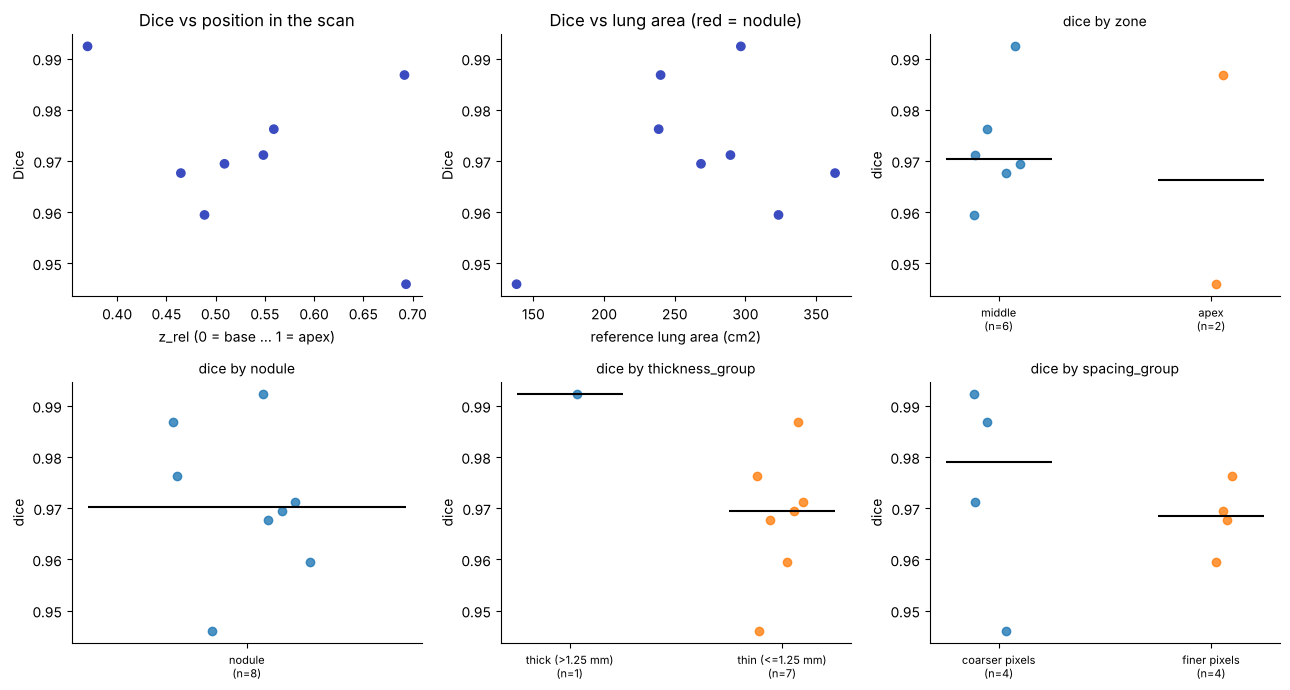

In [36]:
def strip_by_group(ax, data, by, metric="dice"):
    """Strip plot with the median per group and the group size in the tick label."""
    groups = [g for g in data[by].astype("category").cat.categories if (data[by] == g).any()]
    rng = np.random.default_rng(0)
    for k, g in enumerate(groups):
        v = data.loc[data[by] == g, metric].dropna().to_numpy()
        ax.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, alpha=0.8)
        if len(v):
            ax.hlines(np.median(v), k - 0.25, k + 0.25, color="k")
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"{g}\n(n={(data[by] == g).sum()})" for g in groups], fontsize=8)
    ax.set_ylabel(metric); ax.set_title(f"{metric} by {by}", fontsize=10)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes[0, 0].scatter(df["z_rel"], df["dice"], c=df["has_nodule"], cmap="coolwarm")
axes[0, 0].set(xlabel="z_rel (0 = base ... 1 = apex)", ylabel="Dice", title="Dice vs position in the scan")
axes[0, 1].scatter(df["area_gt_cm2"], df["dice"], c=df["has_nodule"], cmap="coolwarm")
axes[0, 1].set(xlabel="reference lung area (cm2)", ylabel="Dice", title="Dice vs lung area (red = nodule)")
for ax, by in zip([axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]], ["zone", "nodule", "thickness_group", "spacing_group"]):
    strip_by_group(ax, df, by)
plt.tight_layout(); plt.show()

> 🧠 **Question:** suppose Dice is clearly lower on thick-slice scans (or one subgroup of patients). (a) Is that already evidence of a
> "biased" model? (b) What would you check before claiming it? (c) What does it mean for a *deployed* model - what do you write in the
> model card, and what do you do in the hospital where 80% of the scans are thick?

**Answer.** (a) Not yet: with few cases per group a difference can be pure chance, and groups are confounded (thick-slice scans may also be
the apex slices, or older scanners, or sicker patients). (b) Show `n`, add confidence intervals (bootstrap below), check the confounders (cross-tabulate or
compare within the same `zone`), and look at the images. (c) A subgroup with a lower performance is a *limitation to document and
monitor*: the model card states the subgroups evaluated, the number of cases, and the performance with uncertainty. For the
hospital with mostly thick scans the *local* performance is the relevant one - which is why a local validation before deployment is
needed. It is the same logic as for fairness across age, sex or ethnicity (seminar): aggregate metrics hide subgroup failures, and
you can only detect the groups that you measured, so collect the metadata.

### 🚀 Challenge (additional) - bootstrap confidence interval of the mean Dice
With `n` test cases the mean Dice is itself a random quantity. **Bootstrap**: resample the cases with replacement `N_BOOT` times, compute the mean each time,
take the 2.5th and 97.5th percentiles. Write `bootstrap_ci(values, n_boot, alpha=0.05, seed=0)`, then compute the interval for the whole test set and for each `zone`.
What happens to the width of the interval for small groups?

<details>
<summary>💡 Hint 1</summary>

`rng.choice(values, size=(n_boot, len(values)), replace=True)` gives all resamples at once; then average over `axis=1`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])`.

</details>

In [37]:
def bootstrap_ci(values, n_boot=N_BOOT, alpha=0.05, seed=0):
    """Percentile bootstrap CI of the mean of `values` (NaN ignored)."""
    values = np.asarray(values, float)
    values = values[~np.isnan(values)]
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return tuple(np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

lo, hi = bootstrap_ci(df["dice"])
print(f"All test cases (n={df['dice'].notna().sum()}): mean Dice {df['dice'].mean():.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")
for z, sub in df.groupby("zone", observed=True):
    lo, hi = bootstrap_ci(sub["dice"])
    print(f"  {z:7s} (n={sub['dice'].notna().sum():2d}): mean {sub['dice'].mean():.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")

All test cases (n=8): mean Dice 0.971, 95% CI [0.961, 0.980]
  middle  (n= 6): mean 0.973, 95% CI [0.965, 0.981]
  apex    (n= 2): mean 0.966, 95% CI [0.946, 0.987]


**Answer.** The interval for a group shrinks roughly with `1/sqrt(n)`: with 5 cases it is so wide that "apex is worse than middle" cannot be claimed;
with 30 it can. The percentile bootstrap is crude for tiny `n` (it cannot produce values outside the observed range) but is the best quick tool for per-patient
metrics. Note that resampling is done **per patient**, which is why one slice per patient is convenient: with several slices per patient you must resample patients, not slices.

## 8. Post-processing: clean the prediction
A segmentation network predicts every pixel independently. Typical artefacts: small isolated islands (false positives somewhere in the abdomen or in
the table), and holes inside the lung (vessels or nodules classified as non-lung). Simple rules from anatomy clean them:
* `KeepLargestConnectedComponent(applied_labels=[1], num_components=N)` keeps the `N` biggest blobs of label 1;
* `FillHoles(applied_labels=[1])` fills the holes inside.

How many components should we keep for **two lungs**? Think before you read the exercise.

### ✏️ Exercise 8.1 - apply post-processing and re-measure
Build the `post` transform and apply it to every predicted mask; then recompute the metrics with `evaluate_masks`.

<details>
<summary>💡 Hint 1</summary>

Label 1 is "lung" in our binary task. A thorax has two lungs, but a single axial slice can show the two lungs as two blobs - not one.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`KeepLargestConnectedComponent(applied_labels=[1], num_components=2)`.

</details>

In [38]:
post = Compose([KeepLargestConnectedComponent(applied_labels=[1], num_components=2),
                FillHoles(applied_labels=[1])])

def postprocess(pred):
    """pred: (H, W) uint8 mask -> cleaned (H, W) uint8 mask."""
    # torch.tensor COPIES the data: MONAI's post-processing may work in place, and torch.as_tensor would share memory with `pred`
    return post(torch.tensor(pred)[None])[0].numpy().astype(np.uint8)

n_comp = lambda m: int(ndi.label(m, structure=np.ones((3, 3)))[1])   # 8-connectivity, like MONAI's default
preds_pp = np.stack([postprocess(p) for p in res["pred"]])
df_pp = evaluate_masks(preds_pp, res["label"], test_meta)

/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


In [39]:
# Check 8.1
assert preds_pp.shape == res["pred"].shape and set(np.unique(preds_pp)) <= {0, 1}, "post-processing must return binary masks of the same shape"
assert all(n_comp(m) <= 2 for m in preds_pp), "at most 2 connected components should remain"
assert (preds_pp.sum(axis=(1, 2)) > 0).sum() >= (res["pred"].sum(axis=(1, 2)) > 0).sum(), "post-processing must not delete a whole non-empty prediction"
print("✅ Exercise 8.1 passed")

✅ Exercise 8.1 passed


In [40]:
cmp = pd.DataFrame({"case_id": df["case_id"],
                    "n_comp": [n_comp(m) for m in res["pred"]], "n_comp_pp": [n_comp(m) for m in preds_pp],
                    "dice": df["dice"], "dice_pp": df_pp["dice"], "hd95": df["hd95_mm"], "hd95_pp": df_pp["hd95_mm"]})
cmp["d_hd95"] = cmp["hd95_pp"] - cmp["hd95"]
print(cmp.round(3).to_string(index=False))
print(f"\nmean Dice {df['dice'].mean():.4f} -> {df_pp['dice'].mean():.4f} | median HD95 {df['hd95_mm'].median():.2f} -> {df_pp['hd95_mm'].median():.2f} mm")

  case_id  n_comp  n_comp_pp  dice  dice_pp   hd95  hd95_pp  d_hd95
case_0010       7          2 0.968    0.974 30.859    6.172 -24.688
case_0020       4          2 0.946    0.954 11.065    3.494  -7.571
case_0030       4          2 0.976    0.979 15.636   12.327  -3.309
case_0040       2          2 0.987    0.987  1.481    1.481   0.000
case_0050       3          2 0.971    0.978 13.432   10.722  -2.710
case_0060       8          2 0.959    0.961 14.737   11.583  -3.154
case_0070       2          2 0.992    0.992  1.406    1.406   0.000
case_0080       2          2 0.969    0.973 15.789   11.425  -4.365

mean Dice 0.9711 -> 0.9749 | median HD95 14.08 -> 8.45 mm


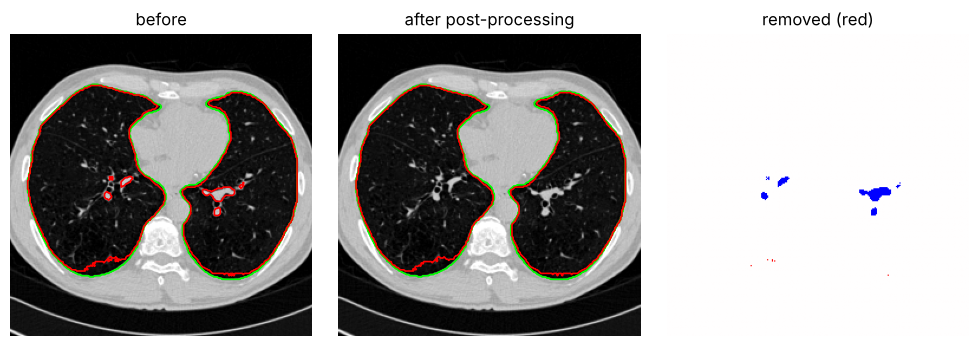

In [41]:
# A case where it helps: largest HD95 improvement (if nothing changed, inject an artificial island to show the principle)
gain = -(cmp["d_hd95"].fillna(0))
i = int(gain.idxmax())
before, after = res["pred"][i].copy(), preds_pp[i]
if gain.max() <= 0:
    before = before | disc(before.shape, 8, 8, 3).astype(np.uint8)       # fake FP island in a corner
    after = postprocess(before)
    print("No case changed with this model: showing an artificial FP island on", cmp.case_id[i])
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
overlay(axes[0], res["image"][i], res["label"][i], before); axes[0].set_title("before")
overlay(axes[1], res["image"][i], res["label"][i], after); axes[1].set_title("after post-processing")
axes[2].imshow((before.astype(int) - after.astype(int)).T, cmap="bwr", vmin=-1, vmax=1); axes[2].set_title("removed (red)"); axes[2].axis("off")
plt.tight_layout(); plt.show()

> ⚠️ **Pitfall (code):** `torch.as_tensor(array)` shares memory with the numpy array, and some MONAI post-transforms modify their input in place. Use
> `torch.tensor(array)` (a copy) whenever the original must survive - otherwise your "before" is silently overwritten and the comparison shows no change.

> ⚠️ **Pitfall:** post-processing is a **prior** about anatomy - and priors fail on the exceptions. Keep 2 components: a slice through the lung apex may show only
> one lung blob, or one lung may be split in two (fissures, a large vessel); after a **pneumonectomy** one lung is legitimately missing (the model
> may then predict the empty side: it is correct!); in 3D the rule becomes "two components", plus a hole filler that must not fill a bulla or a cavity.
> Also remember the rule from section 1: if you pick the post-processing looking at the test set, you are tuning on it.

In [42]:
# 🔍 how many components to keep? (look at what the choice does on this test set)
rows = []
for k in [1, 2, 3, 5]:
    t = Compose([KeepLargestConnectedComponent(applied_labels=[1], num_components=k), FillHoles(applied_labels=[1])])
    pp = np.stack([t(torch.tensor(p)[None])[0].numpy().astype(np.uint8) for p in res["pred"]])
    e = evaluate_masks(pp, res["label"], test_meta)
    rows.append({"num_components": k, "mean Dice": e["dice"].mean(), "min Dice": e["dice"].min(), "median HD95 (mm)": e["hd95_mm"].median()})
rows.append({"num_components": "none", "mean Dice": df["dice"].mean(), "min Dice": df["dice"].min(), "median HD95 (mm)": df["hd95_mm"].median()})
pd.DataFrame(rows).round(4).set_index("num_components")

/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)
/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)
/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since ve

/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


,mean Dice,min Dice,median HD95 (mm)
num_components,,,
1,0.7058,0.6528,127.2460
2,0.9749,0.9540,8.4468
3,0.9735,0.9458,11.2243
5,0.9734,0.9459,11.1775
none,0.9711,0.9459,14.0843


### 🔍 Explore
* `num_components=1` is the default in many tutorials (single organ, e.g. liver). What does it do to the lungs?
* Apply only `FillHoles`: does it change the area? Which structures inside the lung does it fill, and is that what the reference does?
* Try `connectivity=1` (4-neighbours) vs `2` in `KeepLargestConnectedComponent`: when does it matter?

## 9. Robustness: what if the input changes?
Our test set comes from the same distribution as the training set (same dataset, same preprocessing). A hospital is **not** the same distribution:
a different scanner, a different reconstruction kernel, a mis-set window, a patient lying prone. We stress-test the model by **perturbing the test images**
and measuring the Dice again. (Geometric perturbations are applied to image *and* reference, so the right answer is still well defined.)

Our array axes are `[x, y]` = (left-right, anterior-posterior), so in a `(N, 1, H, W)` tensor axis `-2` is the **left-right** axis.

### ✏️ Exercise 9.1 - implement a noise perturbation
Complete `noisy(std)`: add Gaussian noise (standard deviation `std`, in units of the normalised `[0, 1]` intensity) to the image, clip back to `[0, 1]`.
Use a seeded generator so that the test is reproducible. Perturbation functions take and return `(x, y)`.

<details>
<summary>💡 Hint 1</summary>

`torch.randn(shape, generator=g)` draws N(0, 1) samples; multiply by `std` and add to `x`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`(x + std * torch.randn(x.shape, generator=g)).clamp(0, 1)`

</details>

In [43]:
X = torch.as_tensor(res["image"])[:, None]      # (N, 1, H, W) normalised images
Y = torch.as_tensor(res["label"])[:, None]      # (N, 1, H, W) reference masks

def noisy(std, seed=0):
    def fn(x, y):
        g = torch.Generator().manual_seed(seed)
        return (x + std * torch.randn(x.shape, generator=g)).clamp(0, 1), y
    return fn

In [44]:
# Check 9.1
_xn, _yn = noisy(0.1)(X, Y)
assert _xn.shape == X.shape and _xn.min() >= 0 and _xn.max() <= 1, "keep the shape and clip to [0, 1]"
assert 0.04 < float((_xn - X).std()) < 0.11, "the noise standard deviation should be close to 0.1 (before clipping)"
assert torch.equal(noisy(0.1)(X, Y)[0], _xn), "the noise must be reproducible (seeded generator)"
print("✅ Exercise 9.1 passed")

✅ Exercise 9.1 passed


In [45]:
def lowres(factor):
    """Simulate a lower-resolution acquisition: downsample then upsample back (blur)."""
    def fn(x, y):
        small = F.interpolate(x, scale_factor=1 / factor, mode="bilinear", align_corners=False)
        return F.interpolate(small, size=x.shape[-2:], mode="bilinear", align_corners=False), y
    return fn

geom = lambda f: (lambda x, y: (f(x), f(y)))
PERTURBATIONS = {
    "clean (reference)": lambda x, y: (x, y),
    "noise std 0.05": noisy(0.05), "noise std 0.1": noisy(0.1), "noise std 0.2": noisy(0.2),
    "low resolution /2": lowres(2), "low resolution /4": lowres(4),
    "left-right flip": geom(lambda t: torch.flip(t, dims=(-2,))),
    "rotate 90 deg": geom(lambda t: torch.rot90(t, k=1, dims=(-2, -1))),
    "rotate 180 deg (prone-like)": geom(lambda t: torch.rot90(t, k=2, dims=(-2, -1))),
}
# input windows: they change the *preprocessing*, so we re-run the loading pipeline with another HU window
WINDOWS = {"mediastinal window [-160, 240]": (-160, 240), "bone window [-450, 1050]": (-450, 1050)}

robust = {}
for name, fn in PERTURBATIONS.items():
    xp, yp = fn(X, Y)
    _, pp = predict_batch(model, xp)
    robust[name] = np.array([dice_np(p, g) for p, g in zip(pp, yp[:, 0].numpy())])
for name, (lo, hi) in WINDOWS.items():
    rw = predict_dataset(model, test_files, get_transforms(IMG_SIZE, lo, hi))
    robust[name] = np.array([dice_np(p, g) for p, g in zip(rw["pred"], rw["label"])])

rob = pd.DataFrame({"mean Dice": {k: np.nanmean(v) for k, v in robust.items()}, "worst case": {k: np.nanmin(v) for k, v in robust.items()}})
print(rob.round(3).to_string())

nvImageCodec is not available; skipping pydicom decoder plugin registration.


/usr/local/lib/python3.13/site-packages/monai/data/image_reader.py:1166: UserWarning: NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
  warnings.warn(


nvImageCodec is not available; skipping pydicom decoder plugin registration.


                                mean Dice  worst case
clean (reference)                   0.971       0.946
noise std 0.05                      0.969       0.947
noise std 0.1                       0.967       0.947
noise std 0.2                       0.962       0.929
low resolution /2                   0.959       0.858
low resolution /4                   0.944       0.766
left-right flip                     0.969       0.944
rotate 90 deg                       0.909       0.622
rotate 180 deg (prone-like)         0.965       0.930
mediastinal window [-160, 240]      0.838       0.525
bone window [-450, 1050]            0.762       0.364


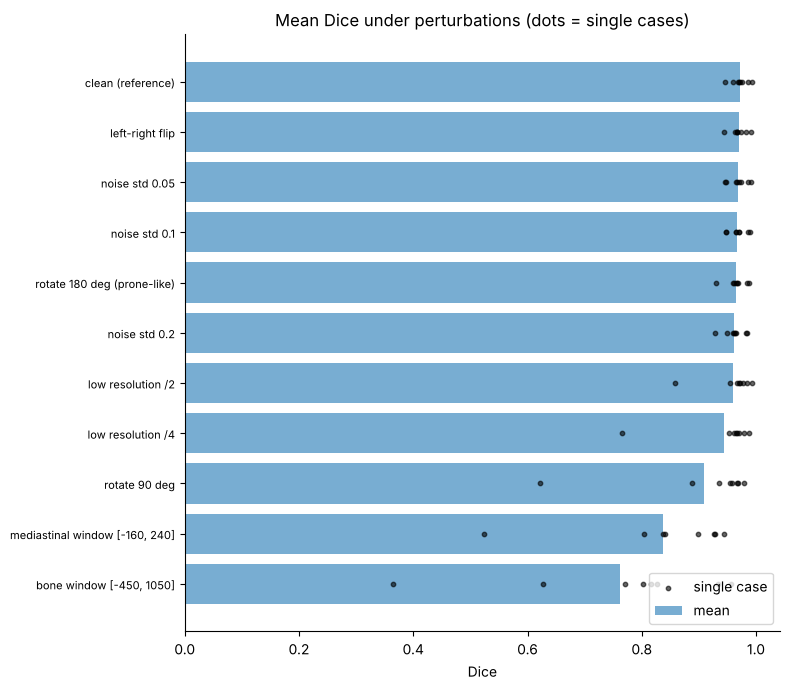

In [46]:
order = rob["mean Dice"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.5))
ax.barh(range(len(order)), rob.loc[order, "mean Dice"], color="tab:blue", alpha=0.6, label="mean")
for k, name in enumerate(order):
    ax.scatter(robust[name], np.full(len(robust[name]), k), color="k", s=10, alpha=0.6, label="single case" if k == 0 else None)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8); ax.set_xlabel("Dice"); ax.legend(loc="lower right")
ax.set_title("Mean Dice under perturbations (dots = single cases)")
plt.tight_layout(); plt.show()

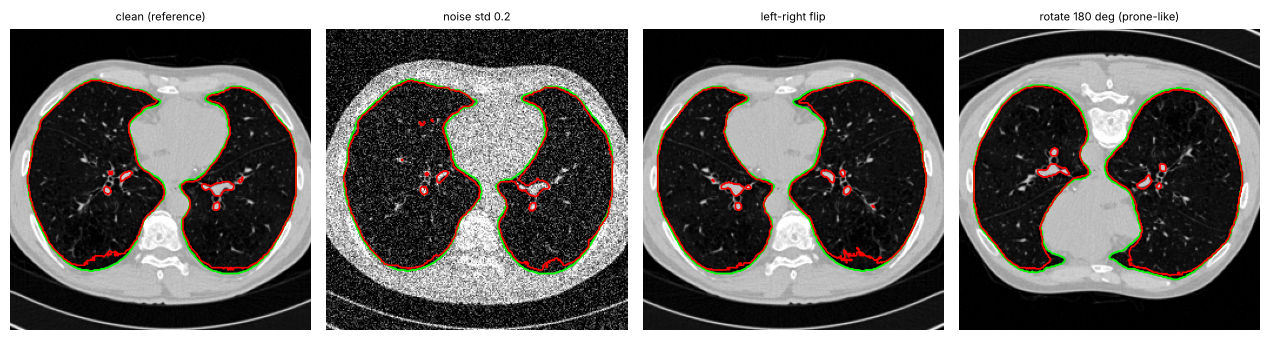

In [47]:
# What does the model see? One case under a few of the perturbations
show = ["clean (reference)", "noise std 0.2", "left-right flip", "rotate 180 deg (prone-like)"]
fig, axes = plt.subplots(1, len(show), figsize=(3.2 * len(show), 3.4))
for ax, name in zip(axes, show):
    xp, yp = PERTURBATIONS[name](X[:1], Y[:1])
    _, pp = predict_batch(model, xp)
    overlay(ax, xp[0, 0].numpy(), yp[0, 0].numpy(), pp[0]); ax.set_title(name, fontsize=8)
plt.tight_layout(); plt.show()

> 🧠 **Question:** which of these perturbations can really happen in a hospital deployment? Rank them by likelihood. Which one is *not an
> acquisition problem at all* but a **bug in our own software**? (Think about what happens if the web app on day 5 does not apply
> the same HU window as the training pipeline.)

**Answer.** Very likely: different noise level (dose, reconstruction kernel, slice thickness), different resolution (pixel spacing, field of view), and a wrong or
missing window. *Prone* scans (180 deg after display convention) do occur in screening/CT colonography, and flips come from wrong orientation handling in the
DICOM/NIfTI conversion (day 1: LPS vs RAS!). 90 deg rotation is rarer but happens with careless array handling. The **wrong HU window** is the training-serving skew:
nothing is wrong with the scanner, our own preprocessing is. The usual cause is a model trained on `[-1000, 400] -> [0, 1]` and an app that forgets to clip or scales
with min/max of the image. It is silent: no error message, only worse masks. Day 4 (06_inference_and_packaging) turns the preprocessing into a single function that is
shared by training, evaluation and the app. Remedies: augmentation that covers the plausible variations (flips/rotations/noise/intensity), input sanity checks
(is the image in the expected HU range?), and monitoring in production.

### 🔍 Explore
* Add your own perturbation to `PERTURBATIONS`: a constant intensity shift (`x + 0.1`), a contrast change (`x ** 0.7`), a random black rectangle
  (a "pacemaker artefact"), a 15 deg rotation... and re-run the loop. Which one hurts most?
* Evaluate also the *HD95* under a perturbation: does Dice hide something?
* Which perturbation could the *training augmentation* (`RandAffined(rotate_range=0.15)`, noise std 0.02) have prepared the model for?

## 10. Is deep learning actually better? A classical baseline
On day 1 you segmented the lungs with a threshold. We re-implement it compactly and evaluate it with **the same metrics on the same test cases**.
A fair baseline is a scientific habit: if a 10-line threshold gets within 0.01 Dice, the neural network is not worth its complexity.
The method works on the *raw HU slice at the original resolution*; we then resize its mask like the labels (nearest neighbour).

In [48]:
def classical_lung_mask(hu, thr=-400):
    """Threshold baseline on a raw HU slice: air-like pixels, drop air connected to the image border (outside the body,
    padding), keep the two biggest components, fill holes."""
    lab, n = ndi.label(hu < thr)
    outside = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
    sizes = np.bincount(lab.ravel(), minlength=n + 1).astype(float)
    sizes[outside] = 0
    sizes[0] = 0                                           # label 0 = pixels above the threshold
    biggest = np.argsort(sizes)[-2:]
    mask = np.isin(lab, biggest[sizes[biggest] > 0])
    return ndi.binary_fill_holes(mask).astype(np.uint8)

to_net_size = Resize(spatial_size=(IMG_SIZE, IMG_SIZE), mode="nearest")
loader = LoadImage(image_only=True)
preds_cl = np.stack([to_net_size(torch.as_tensor(classical_lung_mask(np.asarray(loader(f["image"])).astype(np.float32)))[None])[0].numpy().astype(np.uint8)
                     for f in test_files])
df_cl = evaluate_masks(preds_cl, res["label"], test_meta)

both = pd.concat({"U-Net": summary_table(df).loc[["mean", "median", "worst"]], "threshold": summary_table(df_cl).loc[["mean", "median", "worst"]]}, axis=1)
both

nvImageCodec is not available; skipping pydicom decoder plugin registration.


/usr/local/lib/python3.13/site-packages/monai/data/image_reader.py:1166: UserWarning: NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


U-Net                       threshold                      
         dice    iou hd95_mm asd_mm      dice    iou hd95_mm asd_mm
mean    0.971  0.944  13.051  1.920     0.980  0.961  15.366  1.758
median  0.970  0.942  14.084  1.869     0.980  0.961  13.368  1.491
worst   0.946  0.897  30.859  3.777     0.948  0.902  49.057  4.799

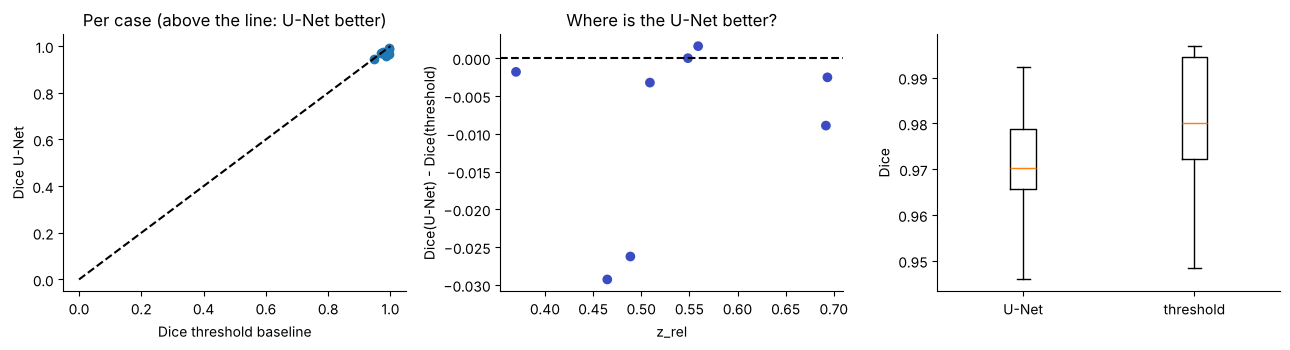

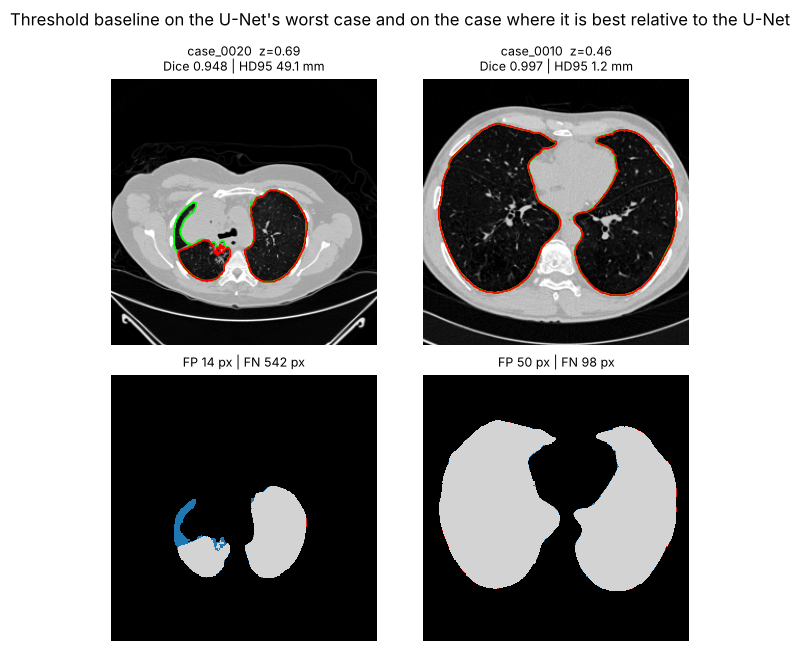

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].scatter(df_cl["dice"], df["dice"]); axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set(xlabel="Dice threshold baseline", ylabel="Dice U-Net", title="Per case (above the line: U-Net better)")
axes[1].scatter(df["z_rel"], df["dice"] - df_cl["dice"], c=df["has_nodule"], cmap="coolwarm"); axes[1].axhline(0, color="k", ls="--")
axes[1].set(xlabel="z_rel", ylabel="Dice(U-Net) - Dice(threshold)", title="Where is the U-Net better?")
axes[2].boxplot([df["dice"].dropna(), df_cl["dice"].dropna()]); axes[2].set_xticklabels(["U-Net", "threshold"]); axes[2].set_ylabel("Dice")
plt.tight_layout(); plt.show()

i_cl = int(np.nanargmin((df["dice"] - df_cl["dice"]).to_numpy()))      # the case where the baseline is relatively best
show_cases([worst_ids[0], i_cl], preds=preds_cl, table=test_meta.merge(df_cl, on="case_id"), title="Threshold baseline on the U-Net's worst case and on the case where it is best relative to the U-Net")

> 🧠 **Question:** is the U-Net clearly better? Where does the threshold method fail, and *where does it look better than it is*? Hint: how were the
> LUNA16 reference masks produced?

**Answer.** On real chest CT a threshold + connected components typically reaches a high Dice on mid-chest slices with healthy lungs, and fails where the
lung is **not** dark: consolidations, effusion, dense nodules at the pleura, and where lungs touch the trachea (merging) or the colon/stomach gas appears
(abdominal slices: extra air blobs). The U-Net learns these cases (and the exact vessel/pleura convention). Crucial caveat: the LUNA16 reference masks come
from an automatic, *intensity-based* algorithm, so the reference **agrees with a threshold by construction** and the baseline is flattered - that is a
case of an evaluation reference that is not independent of the method under test. For an honest comparison you would need expert-corrected
references, at least for a subset. Also compare the *cost*: 10 lines, no GPU, no training data vs a trained network that needs a validation set,
deployment and monitoring.

## 11. Challenges
### 🚀 Challenge 1 (additional) - test-time augmentation (TTA)
Predict each image several times under small, **invertible** transformations (a left-right flip, rotations by ±0.1 rad), undo the transformation on the probability map,
and average. Does it improve the Dice? Does the *disagreement* between the variants say something? Compare with
[MONAI's TTA tutorial](https://github.com/Project-MONAI/tutorials/blob/main/modules/inverse_transforms_and_test_time_augmentations.ipynb).
`rotate(t, angle)` is given. Write `predict_tta(model, x)` returning the mean probability and the standard deviation over the variants.

<details>
<summary>💡 Hint 1</summary>

For each pair `(forward, inverse)` in `TTA`: predict on `forward(x)`, convert the probability to a tensor of shape `(N, 1, H, W)`, apply `inverse` to bring it
back to the original orientation.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`p, _ = predict_batch(model, fwd(x))`, then `inv(torch.as_tensor(p)[:, None])[:, 0]`; stack over variants and take `.mean(0)` and `.std(0)`.

</details>

In [50]:
def rotate(t, angle):
    """Rotate a batch (N, C, H, W) around the image centre by `angle` radians; zeros are filled in at the borders."""
    c, s = math.cos(angle), math.sin(angle)
    theta = torch.tensor([[c, -s, 0.0], [s, c, 0.0]], dtype=t.dtype).repeat(len(t), 1, 1)
    grid = F.affine_grid(theta, list(t.shape), align_corners=False)
    return F.grid_sample(t, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

flip_lr = lambda t: torch.flip(t, dims=(-2,))
TTA = [(lambda t: t, lambda t: t), (flip_lr, flip_lr),
       (lambda t: rotate(t, 0.1), lambda t: rotate(t, -0.1)), (lambda t: rotate(t, -0.1), lambda t: rotate(t, 0.1))]

In [51]:
def predict_tta(model, x):
    """Mean and std (over the TTA variants) of the lung probability, both (N, H, W)."""
    probs = []
    for fwd, inv in TTA:
        p, _ = predict_batch(model, fwd(x))
        probs.append(inv(torch.as_tensor(p)[:, None])[:, 0])
    probs = torch.stack(probs)
    return probs.mean(0).numpy(), probs.std(0).numpy()

prob_tta, std_tta = predict_tta(model, X)
pred_tta = (prob_tta > 0.5).astype(np.uint8)
df_tta = evaluate_masks(pred_tta, res["label"], test_meta)
print(f"mean Dice: single prediction {df['dice'].mean():.4f} -> TTA {df_tta['dice'].mean():.4f}")
print(f"median HD95 (mm): {df['hd95_mm'].median():.2f} -> {df_tta['hd95_mm'].median():.2f}")

mean Dice: single prediction 0.9711 -> TTA 0.9723
median HD95 (mm): 14.08 -> 12.15


/usr/local/lib/python3.13/site-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


### 🚀 Challenge 2 (additional) - can the model tell us when it is wrong?
In production there is no reference mask. A **quality-control signal** computed from the prediction alone is valuable if it correlates with the
per-case Dice: it allows to flag cases for a human check. Two cheap candidates:
* the **mean entropy** of the softmax map, `H = -p log p - (1-p) log(1-p)`, averaged over the image;
* the **TTA disagreement** (mean of `std_tta`), if you did challenge 1.

Compute the signal for every test case, compute its Spearman correlation with Dice (`scipy.stats.spearmanr`), plot it, and simulate a rule
"flag the 1/3 most uncertain cases for review": what is the mean Dice of the flagged vs the non-flagged cases?

<details>
<summary>💡 Hint 1</summary>

Clip the probabilities away from 0 and 1 before the logarithm. Average the entropy map over the spatial axes `(1, 2)` to get one number per case.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`unc = entropy_map(res["prob"]).mean(axis=(1, 2))`; a negative Spearman correlation with Dice means "more uncertain -> lower Dice" (what we hope).

</details>

mean entropy     : flagged (n=3) mean Dice 0.958 | not flagged (n=5) 0.979
TTA disagreement : flagged (n=3) mean Dice 0.959 | not flagged (n=5) 0.978


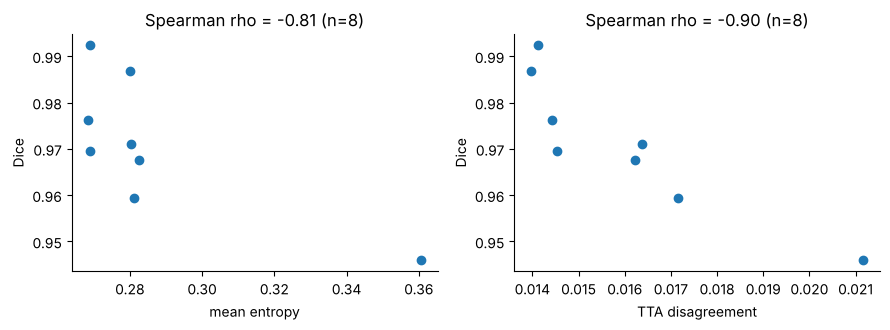

In [52]:
from scipy.stats import spearmanr

def entropy_map(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

signals = {"mean entropy": entropy_map(res["prob"]).mean(axis=(1, 2)), "TTA disagreement": std_tta.mean(axis=(1, 2))}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, unc) in zip(axes, signals.items()):
    ok = df["dice"].notna().to_numpy()
    rho = spearmanr(unc[ok], df["dice"][ok])[0] if ok.sum() > 2 else np.nan
    ax.scatter(unc, df["dice"]); ax.set(xlabel=name, ylabel="Dice", title=f"Spearman rho = {rho:.2f} (n={ok.sum()})")
    flag = unc >= np.quantile(unc, 2 / 3)
    print(f"{name:17s}: flagged (n={flag.sum()}) mean Dice {df['dice'][flag].mean():.3f} | not flagged (n={(~flag).sum()}) {df['dice'][~flag].mean():.3f}")
plt.tight_layout(); plt.show()

**Answer.** On real data the entropy is usually negatively correlated with Dice (uncertain boundaries/pathology), but moderately, and it mostly reflects *boundary
length* (a big lung has a longer uncertain border). Mean entropy is not calibrated either: a model can be confidently wrong (e.g. on a prone scan) - this is
why out-of-distribution checks (is the image in the expected HU range and orientation?) are a different tool. With a few dozen cases the correlation has a wide
confidence interval - never claim a QC rule from n=6. TTA typically gains a little Dice and cuts HD95 outliers; its price is 4x the inference time.

### 🌶️ Going further (optional) - calibration of the pixel probabilities
Softmax outputs look like probabilities but are often over-confident. A **reliability diagram** bins the predicted probability and plots the fraction
of pixels that are truly lung in each bin. A calibrated model lies on the diagonal. Starter code below; extend it with the *expected calibration error*
(ECE), with **temperature scaling** (divide the logits by T fitted on the *validation* set) or with a boundary-only evaluation (most pixels are trivially 0 or 1).

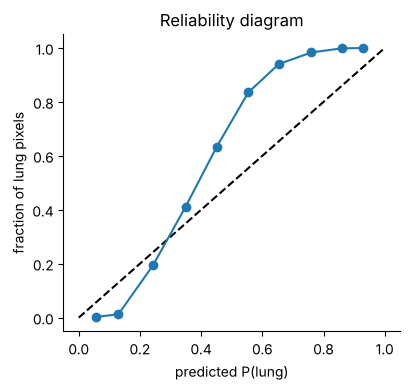

pixels per bin: [330192  63478   4438   2681   2893   4123   7210  17295  61547  30431]


In [53]:
p_all, y_all = res["prob"].ravel(), res["label"].ravel()
bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(p_all, bins) - 1, 0, 9)
conf = np.array([p_all[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)])
acc = np.array([y_all[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)])
cnt = np.array([(idx == b).sum() for b in range(10)])
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], "k--"); ax.plot(conf, acc, "o-"); ax.set(xlabel="predicted P(lung)", ylabel="fraction of lung pixels", title="Reliability diagram")
plt.tight_layout(); plt.show()
print("pixels per bin:", cnt)

### 🌶️ Going further (optional) - evaluate at the original resolution, and pick metrics for another task
* Our metrics live at the network resolution. The clean way back is MONAI's `Invertd` (see the TTA/inverse tutorial linked above): apply the pipeline with
  `Invertd(keys="pred", transform=test_tf, orig_keys="image")` and compute the metrics at 512x512 with the original spacing. Does a 64/256 -> 512 mapping
  change the HD95?
* Read the Metrics Reloaded paper (link below) and its decision "fingerprint": which metrics would you choose for *nodule detection* instead of lung
  segmentation, and why would Dice be the wrong tool? What changes for *quantification* (lung volume) vs *delineation* (radiotherapy)?

## 12. Write-up: the evaluation summary for the model card
On day 4 the model gets a **model card**: a one-page document with intended use, data, performance and limitations. Today's evaluation provides its core.
Numbers come from the tables above; the **limitations** you write yourself, in plain language, for a clinician who will never read this notebook.

### ✏️ Exercise 12.1 - three honest limitations
Fill the list `limitations` with three concrete sentences, each based on something you saw today (for example the worst failure mode, a subgroup, a stress test,
the silver-standard reference, the single-slice 2D design, the dataset size or the single source). Avoid generalities such as "the model may not be perfect".

<details>
<summary>💡 Hint 1</summary>

A good limitation has the form *"condition -> consequence -> evidence"*: "On <what>, the model <fails how>, as seen in <which plot/number>".

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

Candidates: (1) the stratum or failure mode with the worst Dice/HD95; (2) the most damaging perturbation of section 9; (3) the evaluation caveat
(silver-standard reference, one slice per patient, small test set, a single public data source).

</details>

In [54]:
limitations = [
    "Performance is lowest at the extremes of the scan (apex and base slices, small lungs): there Dice is unreliable and the lung area is under- or over-estimated; "
    "see the stratified table (section 7).",
    "The model is sensitive to input preprocessing: a different HU window, strong noise, a flipped or rotated image reduce the Dice substantially (section 9); "
    "inputs must go through the exact training pipeline and be checked for orientation and HU range.",
    "Evaluated on a small single-source test set (one slice per patient, LUNA16 public data) against silver-standard masks produced by an automatic algorithm: "
    "the metrics have wide uncertainty, may be flattered by label bias, and say nothing about other scanners, paediatric patients or pathologies absent from LUNA16.",
]

In [55]:
# Check 12.1
assert len(limitations) == 3, "write exactly three limitations"
assert all(isinstance(s, str) and "____" not in s and len(s) >= 40 for s in limitations), "each limitation: a real sentence (at least 40 characters), no blanks left"
print("✅ Exercise 12.1 passed")

✅ Exercise 12.1 passed


In [56]:
from IPython.display import Markdown, display

zones = group_summary(df, "zone")
weakest = zones["mean"].idxmin() if len(zones) else "n/a"
worst_perturbation = rob["mean Dice"].drop("clean (reference)").idxmin()
summary_md = f"""## Evaluation summary - {cfg['name']}

**Test set:** {len(df)} cases ({DATA_DIR.name}, LUNA16 subset 9, one axial slice per patient). Opened once, after training and model selection. Network input {IMG_SIZE}x{IMG_SIZE}.

| Metric | Mean (SD) | Median | Worst case |
|---|---|---|---|
| Dice | {df['dice'].mean():.3f} ({df['dice'].std():.3f}) | {df['dice'].median():.3f} | {df['dice'].min():.3f} |
| HD95 (mm) | {df['hd95_mm'].mean():.1f} ({df['hd95_mm'].std():.1f}) | {df['hd95_mm'].median():.1f} | {df['hd95_mm'].max():.1f} |
| Average surface distance (mm) | {df['asd_mm'].mean():.2f} ({df['asd_mm'].std():.2f}) | {df['asd_mm'].median():.2f} | {df['asd_mm'].max():.2f} |

* Lung area agreement (cm2): bias {bias:+.2f}, 95% limits of agreement [{loa_low:+.2f}, {loa_high:+.2f}].
* Weakest zone of the scan: **{weakest}** (mean Dice {zones['mean'].min() if len(zones) else float('nan'):.3f}, n={int(zones.loc[weakest, 'n']) if len(zones) else 0}).
* Most damaging perturbation: **{worst_perturbation}** (mean Dice {rob.loc[worst_perturbation, 'mean Dice']:.3f} vs {rob.loc['clean (reference)', 'mean Dice']:.3f} clean).
* Classical threshold baseline: mean Dice {df_cl['dice'].mean():.3f} vs {df['dice'].mean():.3f} for the model.

**Known limitations**
1. {limitations[0]}
2. {limitations[1]}
3. {limitations[2]}
"""
display(Markdown(summary_md))

## Evaluation summary - unet-baseline

**Test set:** 8 cases (real_test, LUNA16 subset 9, one axial slice per patient). Opened once, after training and model selection. Network input 256x256.

| Metric | Mean (SD) | Median | Worst case |
|---|---|---|---|
| Dice | 0.971 (0.015) | 0.970 | 0.946 |
| HD95 (mm) | 13.1 (9.3) | 14.1 | 30.9 |
| Average surface distance (mm) | 1.92 (1.02) | 1.87 | 3.78 |

* Lung area agreement (cm2): bias -6.87, 95% limits of agreement [-32.58, +18.84].
* Weakest zone of the scan: **apex** (mean Dice 0.966, n=2).
* Most damaging perturbation: **bone window [-450, 1050]** (mean Dice 0.762 vs 0.971 clean).
* Classical threshold baseline: mean Dice 0.980 vs 0.971 for the model.

**Known limitations**
1. Performance is lowest at the extremes of the scan (apex and base slices, small lungs): there Dice is unreliable and the lung area is under- or over-estimated; see the stratified table (section 7).
2. The model is sensitive to input preprocessing: a different HU window, strong noise, a flipped or rotated image reduce the Dice substantially (section 9); inputs must go through the exact training pipeline and be checked for orientation and HU range.
3. Evaluated on a small single-source test set (one slice per patient, LUNA16 public data) against silver-standard masks produced by an automatic algorithm: the metrics have wide uncertainty, may be flattered by label bias, and say nothing about other scanners, paediatric patients or pathologies absent from LUNA16.


In [57]:
df.to_csv(WORK_DIR / "test_results.csv", index=False)
(WORK_DIR / "evaluation_summary.md").write_text(summary_md, encoding="utf-8")
print("saved:", WORK_DIR / "test_results.csv", "and", WORK_DIR / "evaluation_summary.md")

saved: /tmp/hi_real2/test_results.csv and /tmp/hi_real2/evaluation_summary.md


## Recap
* One average Dice is not an evaluation: look at the **distribution**, the **tail** and the **median**.
* Use several metrics: overlap (Dice/IoU), boundary (HD95, ASD in **mm**) and a **clinical quantity** (area -> volume, Bland-Altman).
* Look at the images: worst and best cases, FP/FN maps, failure modes - and remember that the reference may be wrong (silver standard).
* Stratify and show `n`; add uncertainty (bootstrap); a subgroup that fails is a limitation to document.
* Post-processing encodes anatomical priors: powerful, but it fails on the exceptions; choose it on validation data, not on the test set.
* Stress-test: noise, windows, orientation. Training-serving skew is a software bug that looks like a model problem (-> day 4).
* Always compare against a simple baseline - and ask whether the reference is independent of it.
* Next: notebook 05 uses these tools to compare experiments (loss, augmentation, architecture) in a controlled way.

**Files written:** `test_results.csv` (per-case table) and `evaluation_summary.md` in `WORK_DIR`; keep them for the model card.

> 📚 **Read more**
> * MONAI metrics: https://docs.monai.io/en/stable/metrics.html and post-processing transforms: https://docs.monai.io/en/stable/transforms.html
> * MONAI tutorials (TTA, inverse transforms): https://github.com/Project-MONAI/tutorials/blob/main/modules/inverse_transforms_and_test_time_augmentations.ipynb
> * Maier-Hein et al., *Metrics Reloaded: recommendations for image analysis validation*: https://arxiv.org/abs/2206.01653
> * Reinke et al., *Common limitations of image processing metrics: a picture story*: https://arxiv.org/abs/2104.05642
> * Bland JM, Altman DG (1986), *Statistical methods for assessing agreement between two methods of clinical measurement*, The Lancet 327:307-310.